# BÀI TẬP GIỮA KỲ – KHOA HỌC DỮ LIỆU TRONG KINH TẾ VÀ KINH DOANH
## Chủ đề 2: Phân tích dữ liệu tiếp thị ngân hàng (Bank Marketing)

**Nguồn dữ liệu:** [Bank Marketing Dataset – Kaggle](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset), tệp `bank.csv`.

**Mục tiêu nghiên cứu:** Phân tích đặc điểm khách hàng và chiến dịch tiếp thị qua điện thoại có liên quan đến việc đăng ký tiền gửi có kỳ hạn (`deposit`). Trên cơ sở đó, xây dựng và đánh giá các mô hình phân loại phục vụ xếp hạng khách hàng trước cuộc gọi, đồng thời đề xuất hướng cải thiện hoạt động tiếp thị.

Nội dung được trình bày theo bốn giai đoạn: (1) thu thập và đánh giá dữ liệu; (2) tiền xử lý và làm sạch; (3) phân tích, kiểm định giả thuyết, trực quan hóa và mô hình hóa; (4) đánh giá kết quả và đề xuất khuyến nghị quản trị.

In [28]:
# ============ KHỐI 0: THƯ VIỆN VÀ CẤU HÌNH HỆ THỐNG ============
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

# Tắt cảnh báo không cần thiết
warnings.filterwarnings("ignore")

# ---- Cấu hình thực nghiệm (nhóm điều chỉnh tại đây) ----
RANDOM_STATE = 42          # cố định seed để kết quả lặp lại 100%
TEST_SIZE = 0.20           # tỷ lệ tập kiểm tra (80% train, 20% test)
DATA_FILE = "bank.csv"     # cần commit kèm notebook để Run All trong Colab
RAW_URL = "https://raw.githubusercontent.com/hlinhhochoc/Nh-m-2---Topic-2---L-p-Logistics-v-QLCCU-CLC-66B---TOKT1138-126-CLC_57/main/bank.csv"  # bank.csv cần nằm ở thư mục gốc branch main
USE_SCIPY_TESTS = True     # BẬT kiểm định giả thuyết thống kê chính quy (Scipy)
OUTPUT_DIR = "figures_output"

os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150

def save_show(filename, dpi=150):
    """Lưu biểu đồ thành PNG để chèn vào báo cáo PDF và hiển thị ngay trên notebook."""
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=dpi, bbox_inches="tight")
    plt.show()

print("[SUCCESS] Đã khởi tạo thành công thư viện, cấu hình thực nghiệm và thư mục lưu biểu đồ!")

[SUCCESS] Đã khởi tạo thành công thư viện, cấu hình thực nghiệm và thư mục lưu biểu đồ!


# Giai đoạn 1: Thu thập và đánh giá dữ liệu ban đầu

**Mục tiêu:** Xác định nguồn, cấu trúc, kiểu dữ liệu, giá trị thiếu, dữ liệu trùng lặp và phân phối của biến mục tiêu `deposit`.

Bộ dữ liệu gồm **11.162 quan sát** và **17 thuộc tính** trong một tệp CSV. Do dữ liệu được cung cấp dưới dạng một bảng duy nhất nên không cần ghép bảng qua khóa chính hoặc khóa ngoại.

### Từ điển dữ liệu
| STT | Thuộc tính | Kiểu dữ liệu | Nhóm nghiệp vụ | Ý nghĩa |
|:---:|:---|:---:|:---|:---|
| 1 | `age` | Số nguyên | Nhân khẩu học | Tuổi khách hàng |
| 2 | `job` | Danh mục | Nhân khẩu học | Nghề nghiệp (12 nhóm và nhãn `unknown`) |
| 3 | `marital` | Danh mục | Nhân khẩu học | Tình trạng hôn nhân |
| 4 | `education` | Danh mục có thứ bậc | Nhân khẩu học | Trình độ học vấn: primary, secondary, tertiary hoặc unknown |
| 5 | `default` | Nhị phân | Tài chính / tín dụng | Có hay không có tín dụng vỡ nợ |
| 6 | `balance` | Số nguyên | Tài chính / tín dụng | Số dư tài khoản trung bình năm (EUR); giá trị âm biểu thị số dư âm |
| 7 | `housing` | Nhị phân | Tài chính / tín dụng | Có hay không có khoản vay mua nhà |
| 8 | `loan` | Nhị phân | Tài chính / tín dụng | Có hay không có khoản vay cá nhân |
| 9 | `contact` | Danh mục | Tiếp thị hiện tại | Kênh liên hệ: cellular, telephone hoặc unknown |
| 10 | `day` | Số nguyên | Tiếp thị hiện tại | Ngày trong tháng của lần liên hệ gần nhất |
| 11 | `month` | Danh mục | Tiếp thị hiện tại | Tháng của lần liên hệ gần nhất |
| 12 | `duration` | Số nguyên | Tiếp thị hiện tại | Thời lượng cuộc gọi gần nhất, tính bằng giây; chỉ biết sau cuộc gọi |
| 13 | `campaign` | Số nguyên | Tiếp thị hiện tại | Số lần liên hệ trong chiến dịch hiện tại |
| 14 | `pdays` | Số nguyên | Tiếp thị trước đây | Số ngày từ lần liên hệ trước; `-1` nghĩa là chưa từng được liên hệ |
| 15 | `previous` | Số nguyên | Tiếp thị trước đây | Số lần liên hệ trước chiến dịch hiện tại |
| 16 | `poutcome` | Danh mục | Tiếp thị trước đây | Kết quả chiến dịch trước: success, failure, other hoặc unknown |
| 17 | `deposit` | Nhị phân | Biến mục tiêu | Khách hàng có đăng ký tiền gửi có kỳ hạn hay không (yes/no) |

In [29]:
# 1.1. Đọc dữ liệu (thư mục hiện tại -> thư mục notebook -> RAW_URL công khai -> upload Colab)
from pathlib import Path

EXPECTED_COLUMNS = {
    "age", "job", "marital", "education", "default", "balance", "housing", "loan",
    "contact", "day", "month", "duration", "campaign", "pdays", "previous", "poutcome", "deposit"
}

def read_and_validate_csv(path):
    data = pd.read_csv(path)
    missing = EXPECTED_COLUMNS - set(data.columns)
    if missing:
        raise ValueError(f"File {path} thiếu các cột bắt buộc: {sorted(missing)}")
    return data

def load_bank_dataset():
    # Hữu ích khi chạy notebook từ thư mục gốc repo hoặc mở file ở thư mục khác.
    candidates = [Path(DATA_FILE), Path.cwd() / DATA_FILE]
    try:
        candidates.append(Path(__file__).resolve().parent / DATA_FILE)
    except NameError:  # __file__ không tồn tại trong Jupyter/Colab
        pass
    for path in dict.fromkeys(candidates):
        if path.is_file():
            print(f"Đọc dữ liệu từ: {path.resolve()}")
            return read_and_validate_csv(path)

    if RAW_URL.strip():
        try:
            print("Đọc dữ liệu từ RAW_URL")
            return read_and_validate_csv(RAW_URL.strip())
        except Exception as e:
            print(f"Không tải được RAW_URL ({e}).")

    try:
        from google.colab import files
        print("Chưa tìm thấy bank.csv. Hãy chọn file bank.csv để tải lên Colab:")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("Bạn chưa chọn file dữ liệu.")
        uploaded_name = next(iter(uploaded))
        if Path(uploaded_name).name.lower() != "bank.csv":
            print(f"Đang đọc file đã tải lên: {uploaded_name}")
        return read_and_validate_csv(uploaded_name)
    except ImportError as e:
        raise FileNotFoundError(
            "Không tìm thấy bank.csv. Hãy đặt bank.csv cùng thư mục làm việc/notebook, "
            "điền RAW_URL bằng đường dẫn CSV raw công khai, hoặc chạy trên Colab để upload."
        ) from e

df = load_bank_dataset()
assert df.shape[0] > 0, "Dữ liệu rỗng"
print(f"Số quan sát: {df.shape[0]:,} | Số thuộc tính: {df.shape[1]}")
df.head()

Đọc dữ liệu từ RAW_URL
Số quan sát: 11,162 | Số thuộc tính: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [30]:
# 1.2. Bảng kiểm tra cấu trúc, kiểu dữ liệu và khuyết thiếu (kể cả khuyết thiếu ẩn)
records = []
for col in df.columns:
    is_text = not pd.api.types.is_numeric_dtype(df[col])
    note = "Bình thường"
    if is_text:
        n_unk = (df[col].str.lower() == "unknown").sum()
        if n_unk > 0:
            note = f"Nhãn 'unknown': {n_unk:,} ({n_unk/len(df)*100:.2f}%)"
    elif col == "pdays":
        n = (df[col] == -1).sum()
        note = f"Giá trị đặc biệt -1 (chưa liên hệ trước đó): {n:,} ({n/len(df)*100:.2f}%)"
    elif col == "balance":
        n = (df[col] < 0).sum()
        note = f"Số dư âm: {n:,} ({n/len(df)*100:.2f}%)"
    records.append({"Thuộc tính": col, "Kiểu dữ liệu": "số" if not is_text else "chuỗi",
                    "NaN tường minh": int(df[col].isnull().sum()),
                    "Số giá trị duy nhất": df[col].nunique(), "Ghi chú": note})
inspection = pd.DataFrame(records)
print(inspection.to_string(index=False))

print("\nSố dòng trùng lặp hoàn toàn:", df.duplicated().sum())
print("\nPhân phối biến mục tiêu 'deposit':")
print(pd.concat([df["deposit"].value_counts().rename("Số lượng"),
                 (df["deposit"].value_counts(normalize=True)*100).round(2).rename("Tỷ lệ (%)")], axis=1))

Thuộc tính Kiểu dữ liệu  NaN tường minh  Số giá trị duy nhất                                                     Ghi chú
       age           số               0                   76                                                 Bình thường
       job        chuỗi               0                   12                                  Nhãn 'unknown': 70 (0.63%)
   marital        chuỗi               0                    3                                                 Bình thường
 education        chuỗi               0                    4                                 Nhãn 'unknown': 497 (4.45%)
   default        chuỗi               0                    2                                                 Bình thường
   balance           số               0                 3805                                       Số dư âm: 688 (6.16%)
   housing        chuỗi               0                    2                                                 Bình thường
      loan        chuỗi         

In [31]:
# 1.3. Thống kê mô tả biến định lượng (kèm median, IQR, skewness)
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["IQR"] = desc["75%"] - desc["25%"]
desc["skewness"] = df[num_cols].skew()
desc[["count", "mean", "std", "min", "25%", "median", "75%", "max", "IQR", "skewness"]].round(2)

,count,mean,std,min,25%,median,75%,max,IQR,skewness
age,11162.0,41.23,11.91,18.0,32.0,39.0,49.00,95.0,17.00,0.86
balance,11162.0,1528.54,3225.41,-6847.0,122.0,550.0,1708.00,81204.0,1586.00,8.22
day,11162.0,15.66,8.42,1.0,8.0,15.0,22.00,31.0,14.00,0.11
duration,11162.0,371.99,347.13,2.0,138.0,255.0,496.00,3881.0,358.00,2.14
campaign,11162.0,2.51,2.72,1.0,1.0,2.0,3.00,63.0,2.00,5.55
pdays,11162.0,51.33,108.76,-1.0,-1.0,-1.0,20.75,854.0,21.75,2.45
previous,11162.0,0.83,2.29,0.0,0.0,0.0,1.00,58.0,1.00,7.34


### Nhận xét dữ liệu ban đầu

Kết quả kiểm tra cho thấy dữ liệu không có giá trị khuyết thiếu dạng `NaN` và không có dòng trùng lặp hoàn toàn. Một số trường phân loại dùng nhãn `unknown` để biểu thị thông tin chưa xác định; đây là khuyết thiếu ẩn cần được xem xét riêng. Giá trị `pdays = -1` là mã trạng thái “chưa từng liên hệ”, không phải số ngày thực. Tỷ lệ hai lớp của `deposit` gần cân bằng; do đó Accuracy có thể được xem xét cùng Precision, Recall, F1 và ROC-AUC để đánh giá mô hình toàn diện hơn.

# Giai đoạn 2: Tiền xử lý và làm sạch dữ liệu

Để hạn chế rò rỉ dữ liệu, dữ liệu được chia thành tập train và test trước khi học các tham số tiền xử lý. Ngưỡng IQR, mode dùng cho imputation, danh sách cột One-Hot và `RobustScaler` được xác định trên tập train; các tham số này sau đó được áp dụng cho tập test. Những phép biến đổi theo quy tắc cố định, chẳng hạn tạo cờ từ `pdays = -1`, không cần ước lượng tham số từ dữ liệu.

In [32]:
# 2.1. MINH CHỨNG ngoại lệ bằng IQR (phục vụ trình bày; chỉ mô tả, chưa thay đổi dữ liệu)
rows = []
for col in ["age", "balance", "duration", "campaign", "pdays", "previous"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"Biến": col, "Q1": q1, "Median": df[col].median(), "Q3": q3, "IQR": iqr,
                 "Ngưỡng dưới": round(lo, 2), "Ngưỡng trên": round(hi, 2),
                 "Số outlier": n_out, "Tỷ lệ (%)": round(n_out / len(df) * 100, 2),
                 "Skewness": round(df[col].skew(), 2)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nLưu ý: pdays và previous có IQR rất nhỏ vì ~3/4 khách hàng chưa từng được liên hệ (pdays=-1, previous=0),"
      "\nnên mọi giá trị > 0 bị IQR coi là outlier. Đây là hiệu ứng của mã đặc biệt, không phải lỗi dữ liệu.")

    Biến    Q1  Median      Q3     IQR  Ngưỡng dưới  Ngưỡng trên  Số outlier  Tỷ lệ (%)  Skewness
     age  32.0    39.0   49.00   17.00         6.50        74.50         171       1.53      0.86
 balance 122.0   550.0 1708.00 1586.00     -2257.00      4087.00        1055       9.45      8.22
duration 138.0   255.0  496.00  358.00      -399.00      1033.00         636       5.70      2.14
campaign   1.0     2.0    3.00    2.00        -2.00         6.00         601       5.38      5.55
   pdays  -1.0    -1.0   20.75   21.75       -33.62        53.38        2750      24.64      2.45
previous   0.0     0.0    1.00    1.00        -1.50         2.50        1258      11.27      7.34

Lưu ý: pdays và previous có IQR rất nhỏ vì ~3/4 khách hàng chưa từng được liên hệ (pdays=-1, previous=0),
nên mọi giá trị > 0 bị IQR coi là outlier. Đây là hiệu ứng của mã đặc biệt, không phải lỗi dữ liệu.


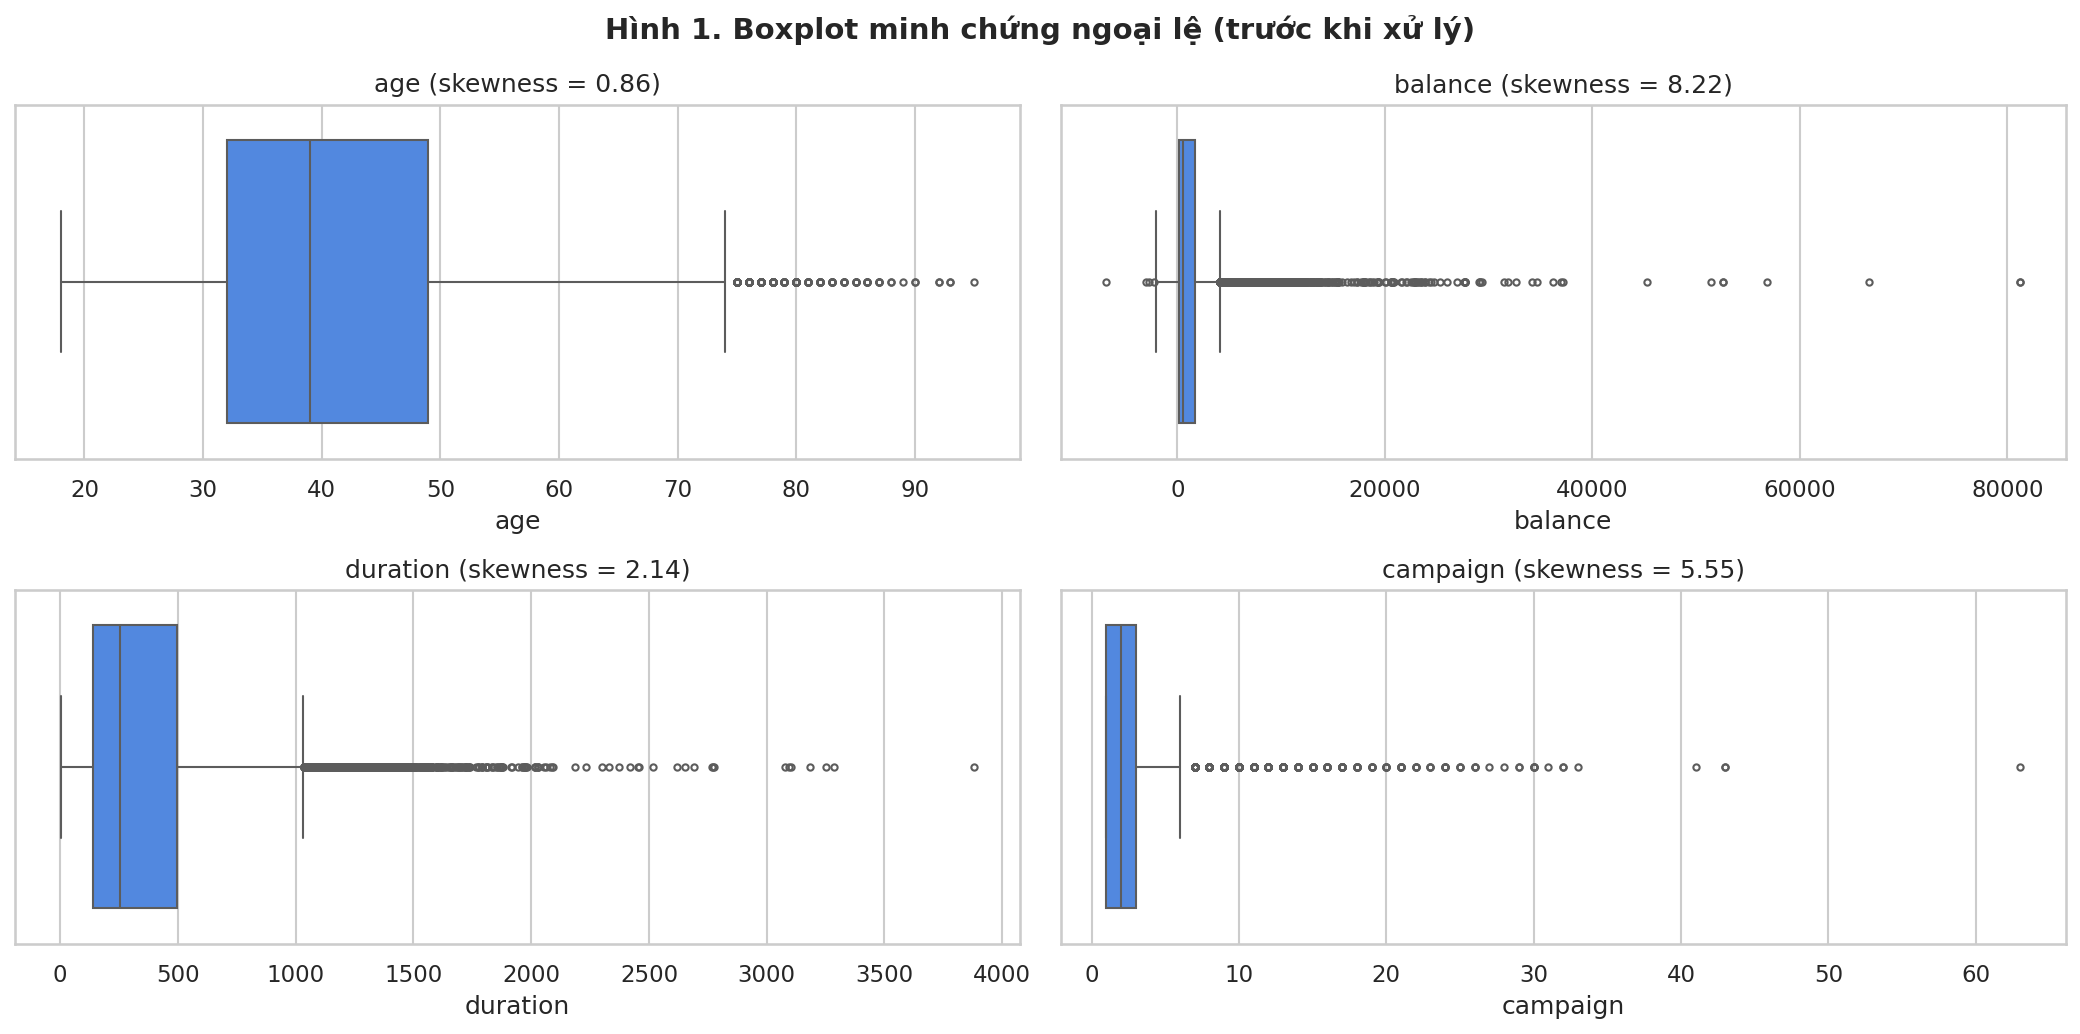

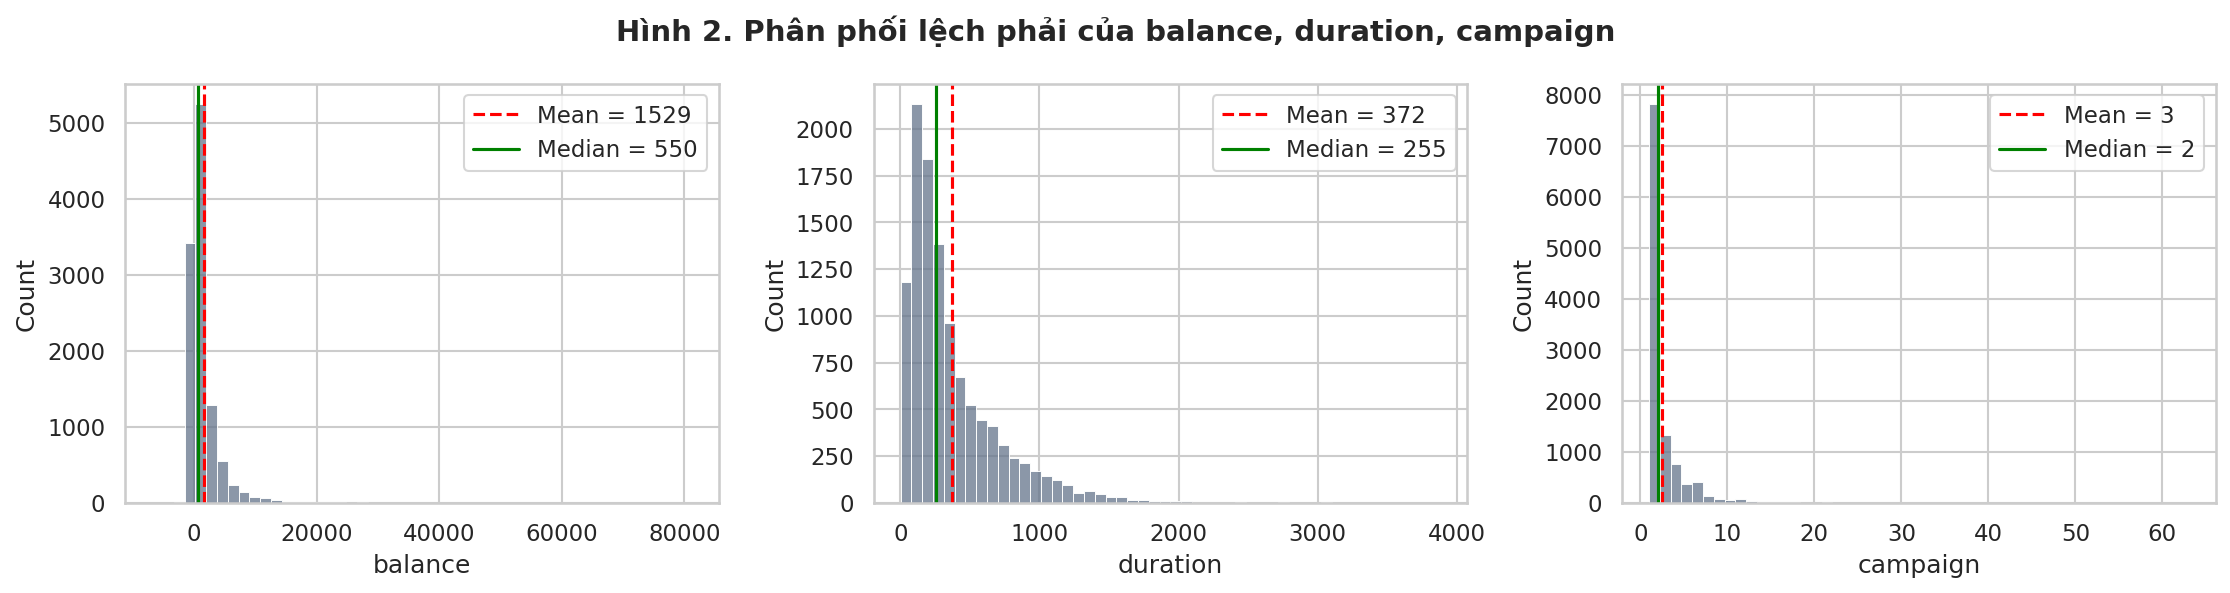

In [33]:
# Biểu đồ minh chứng 1: boxplot các biến có outlier
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
fig.suptitle("Hình 1. Boxplot minh chứng ngoại lệ (trước khi xử lý)", fontsize=14, fontweight="bold")
for ax, col in zip(axes.ravel(), ["age", "balance", "duration", "campaign"]):
    sns.boxplot(x=df[col], ax=ax, color="#3b82f6", fliersize=3)
    ax.set_title(f"{col} (skewness = {df[col].skew():.2f})")
save_show("fig1_boxplot_outliers.png")

# Biểu đồ minh chứng 2: histogram cho thấy độ lệch phải -> cơ sở chọn median/IQR/RobustScaler
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Hình 2. Phân phối lệch phải của balance, duration, campaign", fontsize=14, fontweight="bold")
for ax, col in zip(axes, ["balance", "duration", "campaign"]):
    sns.histplot(df[col], bins=50, ax=ax, color="#64748b")
    ax.axvline(df[col].mean(), color="red", ls="--", label=f"Mean = {df[col].mean():.0f}")
    ax.axvline(df[col].median(), color="green", ls="-", label=f"Median = {df[col].median():.0f}")
    ax.legend()
save_show("fig2_histogram_skew.png")

### Cơ sở lựa chọn phương pháp tiền xử lý

- `balance`, `duration` và `campaign` có phân phối lệch phải; median và IQR ít bị ảnh hưởng bởi các giá trị cực trị hơn mean và độ lệch chuẩn. `RobustScaler` được sử dụng cho Logistic Regression và KNN vì các mô hình này nhạy với thang đo.
- Các giá trị cực trị có thể phản ánh khách hàng hoặc cuộc gọi thực tế. Vì vậy, notebook không xóa quan sát mà capping một số biến theo ngưỡng 1,5×IQR học từ tập train. `pdays` không được capping vì `-1` là mã trạng thái đặc biệt.
- `unknown` ở `job` và `education` được điền bằng cross-group mode, với mode toàn cục làm phương án dự phòng. `contact` và `poutcome` được giữ như các nhóm phân loại riêng vì nhãn `unknown` có ý nghĩa thông tin. `previous` có phân phối lệch phải mạnh (skewness khoảng 7,34) nhưng không capping vì đây là số lần liên hệ thực tế; `RobustScaler` chỉ giảm ảnh hưởng lên thang đo, không loại bỏ hoàn toàn ảnh hưởng của các giá trị lớn đối với Logistic Regression và KNN. One-Hot Encoding được fit trên train và áp dụng cùng cấu trúc cột cho test.

In [34]:
# ===== CHIA TRAIN/TEST (thực hiện TRƯỚC khi học bất kỳ tham số tiền xử lý nào) =====
# Chia phân tầng theo 'deposit' để hai tập có cùng tỷ lệ yes/no
train_idx, test_idx = train_test_split(
    df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df["deposit"])
df_train = df.loc[train_idx]
df_test = df.loc[test_idx]
print(f"Train: {len(df_train):,} dòng | Test: {len(df_test):,} dòng")
print("Tỷ lệ deposit=yes: train = %.2f%% | test = %.2f%%" % (
    (df_train['deposit']=='yes').mean()*100, (df_test['deposit']=='yes').mean()*100))

Train: 8,929 dòng | Test: 2,233 dòng
Tỷ lệ deposit=yes: train = 47.38% | test = 47.38%


In [35]:
# 2.2. HỌC THAM SỐ TIỀN XỬ LÝ CHỈ TRÊN TẬP TRAIN
# (a) Ngưỡng capping theo IQR. Không capping pdays vì -1 là mã “chưa từng liên hệ”.
cap_cols = ["age", "balance", "duration", "campaign"]
cap_limits = {}
for col in cap_cols:
    q1, q3 = df_train[col].quantile(0.25), df_train[col].quantile(0.75)
    iqr = q3 - q1
    cap_limits[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# (b) Học mode toàn cục và cross-group mode từ train.
# Chỉ dùng nhóm có giá trị hợp lệ; fallback toàn cục nếu nhóm không có mode.
job_mode_all = df_train.loc[df_train["job"] != "unknown", "job"].mode().iloc[0]
edu_mode_all = df_train.loc[df_train["education"] != "unknown", "education"].mode().iloc[0]
valid_job = df_train[df_train["job"] != "unknown"]
valid_edu = df_train[df_train["education"] != "unknown"]
job_by_edu = (valid_job[valid_job["education"] != "unknown"].groupby("education")["job"]
              .agg(lambda s: s.mode().iloc[0]))
edu_by_job = (valid_edu[valid_edu["job"] != "unknown"].groupby("job")["education"]
              .agg(lambda s: s.mode().iloc[0]))
print("Ngưỡng capping (học từ train):")
for k, (lo, hi) in cap_limits.items():
    print(f"  {k:9s}: [{lo:9.2f}, {hi:9.2f}]")

Ngưỡng capping (học từ train):
  age      : [     6.50,     74.50]
  balance  : [ -2236.00,   4052.00]
  duration : [  -395.50,   1024.50]
  campaign : [    -2.00,      6.00]


In [36]:
# 2.3. ÁP DỤNG THAM SỐ ĐÃ HỌC + TẠO ĐẶC TRƯNG
# Hàm chỉ transform, không học tham số từ frame được truyền vào.
def prepare_features(frame):
    f = frame.copy()

    # Điền job chưa biết theo học vấn hợp lệ; nếu không có nhóm phù hợp thì dùng mode train.
    job_guess = f["education"].map(job_by_edu).fillna(job_mode_all)
    f["job_imp"] = f["job"].where(f["job"] != "unknown", job_guess)

    # Điền education chưa biết theo nghề nghiệp đã hoàn thiện; fallback về mode train.
    edu_guess = f["job_imp"].map(edu_by_job).fillna(edu_mode_all)
    f["edu_imp"] = f["education"].where(f["education"] != "unknown", edu_guess)

    # Capping theo ngưỡng IQR của train.
    for col, (lo, hi) in cap_limits.items():
        f[col + "_capped"] = f[col].clip(lower=lo, upper=hi)

    # pdays=-1 là mã đặc biệt, không phải số ngày: tách cờ và nhóm thời gian.
    f["was_contacted_before"] = (f["pdays"] != -1).astype(int)
    f["pdays_group"] = pd.cut(f["pdays"], bins=[-2, -1, 90, 180, 10000],
                              labels=["never", "le90d", "91_180d", "gt180d"]).astype(str)

    # Mã hóa nhị phân và thứ bậc. education đã được điền nên mapping phải đủ.
    for c in ["default", "housing", "loan"]:
        f[c] = (f[c] == "yes").astype(int)
    f["education_ord"] = f["edu_imp"].map({"primary": 1, "secondary": 2, "tertiary": 3})
    if f["education_ord"].isna().any():
        raise ValueError("education_ord còn giá trị thiếu; cần rà soát nhóm education ngoài dự kiến.")
    f["target"] = (f["deposit"] == "yes").astype(int)
    return f

# Chỉ tạo đặc trưng riêng cho train/test sau khi đã split.
train_features = prepare_features(df_train)
test_features = prepare_features(df_test)
nominal = ["job_imp", "marital", "contact", "month", "poutcome", "pdays_group"]
base_cols = ["age_capped", "balance_capped", "day", "duration_capped", "campaign_capped",
             "previous", "was_contacted_before", "default", "housing", "loan", "education_ord"]

# Fit danh sách cột one-hot trên train; test được căn chỉnh theo cùng schema.
X_train_full = pd.get_dummies(train_features, columns=nominal, drop_first=True, dtype=int)
X_test_full = pd.get_dummies(test_features, columns=nominal, drop_first=True, dtype=int)
feature_cols = [c for c in X_train_full.columns if c in base_cols or any(c.startswith(p + "_") for p in nominal)]
X_train_full = X_train_full.reindex(columns=feature_cols + ["target"])
X_test_full = X_test_full.reindex(columns=feature_cols + ["target"], fill_value=0)

# Cùng danh sách biến cho hai tập; cột category chỉ xuất hiện ở test bị bỏ qua.
dummy_cols = [c for c in feature_cols if c not in base_cols]
post_cols = base_cols + dummy_cols                         # có duration (chỉ biết SAU cuộc gọi)
pre_cols = [c for c in post_cols if c != "duration_capped"]
y_train = X_train_full["target"]
y_test = X_test_full["target"]
print(f"Số đặc trưng: pre-call = {len(pre_cols)}, post-call = {len(post_cols)}")
print("Số unknown job/education sau xử lý (train/test):",
      int((train_features["job_imp"] == "unknown").sum()),
      int((train_features["edu_imp"] == "unknown").sum()), "/",
      int((test_features["job_imp"] == "unknown").sum()),
      int((test_features["edu_imp"] == "unknown").sum()))

Số đặc trưng: pre-call = 41, post-call = 42
Số unknown job/education sau xử lý (train/test): 0 0 / 0 0


In [37]:
# 2.4. CHUẨN HÓA bằng RobustScaler (fit trên train, transform test) - dùng cho Logistic Regression và KNN
# Lý do chọn RobustScaler: dùng median và IQR nên ít bị kéo bởi đuôi lệch phải của balance/campaign;
# MinMaxScaler nhạy với giá trị cực đại, StandardScaler dùng mean/std bị ảnh hưởng bởi outlier.
scale_cols = ["age_capped", "balance_capped", "day", "duration_capped", "campaign_capped", "previous"]
scaler = RobustScaler().fit(X_train_full[scale_cols])

def scaled(frame):
    out = frame.copy()
    out[scale_cols] = scaler.transform(frame[scale_cols])
    return out

X_train_scaled_full = scaled(X_train_full)
X_test_scaled_full = scaled(X_test_full)
# Cây quyết định và Random Forest không phụ thuộc thang đo nên dùng dữ liệu chưa chuẩn hóa.
print("Đã chuẩn hóa xong. Ví dụ median/IQR học từ train:")
print(pd.DataFrame({"center(median)": scaler.center_, "scale(IQR)": scaler.scale_}, index=scale_cols).round(2))

Đã chuẩn hóa xong. Ví dụ median/IQR học từ train:
                 center(median)  scale(IQR)
age_capped                 39.0        17.0
balance_capped            552.0      1572.0
day                        15.0        14.0
duration_capped           253.0       355.0
campaign_capped             2.0         2.0
previous                    0.0         1.0


# Giai đoạn 3: Phân tích, kiểm định, trực quan hóa và mô hình hóa

## Phần A – Giả thuyết phân tích

Các giả thuyết được đánh giá bằng tỷ lệ đăng ký theo nhóm và các kiểm định thống kê tương ứng. Kết quả trên dữ liệu quan sát cho biết mức độ liên hệ, không tự nó chứng minh quan hệ nhân quả.

| Mã | Giả thuyết |
|:---:|:---|
| H1 | Phân phối số dư tài khoản của nhóm đăng ký có xu hướng cao hơn nhóm không đăng ký |
| H2 | Tỷ lệ đăng ký khác nhau giữa các nhóm tuổi |
| H3 | Tỷ lệ đăng ký có liên hệ với số lần gọi trong chiến dịch |
| H4 | Tỷ lệ đăng ký khác nhau theo tình trạng vay mua nhà và vay cá nhân |
| H5 | Tỷ lệ đăng ký khác nhau theo kết quả chiến dịch tiếp thị trước (`poutcome`) |
| H6 | Tỷ lệ đăng ký khác nhau giữa các tháng; đồng thời đối chiếu tháng có nhiều cuộc gọi nhất với tỷ lệ đăng ký của tháng đó |

In [38]:
# Hàm tiện ích: bảng quy mô mẫu (n) và tỷ lệ đăng ký (%) theo một biến nhóm
def rate_table(data, by):
    g = data.groupby(by, observed=False)["deposit"]
    t = pd.DataFrame({"n": g.size(), "ty_le_yes_%": g.apply(lambda x: (x == "yes").mean() * 100)})
    return t.round(2)

eda = df.copy()   # EDA mô tả trên toàn bộ dữ liệu (không học tham số nên không gây rò rỉ)
eda["age_group"] = pd.cut(eda["age"], bins=[17, 25, 35, 50, 60, 100],
                          labels=["18-25", "26-35", "36-50", "51-60", "60+"])
overall_rate = (eda["deposit"] == "yes").mean() * 100
print(f"Tỷ lệ đăng ký chung: {overall_rate:.2f}%")

Tỷ lệ đăng ký chung: 47.38%


Median balance theo deposit:
 deposit
no     414.0
yes    733.0
Name: balance, dtype: float64
                     n  ty_le_yes_%
balance_quartile                   
Q1 (thấp nhất)    2792        35.96
Q2                2791        46.22
Q3                2789        49.87
Q4 (cao nhất)     2790        57.49


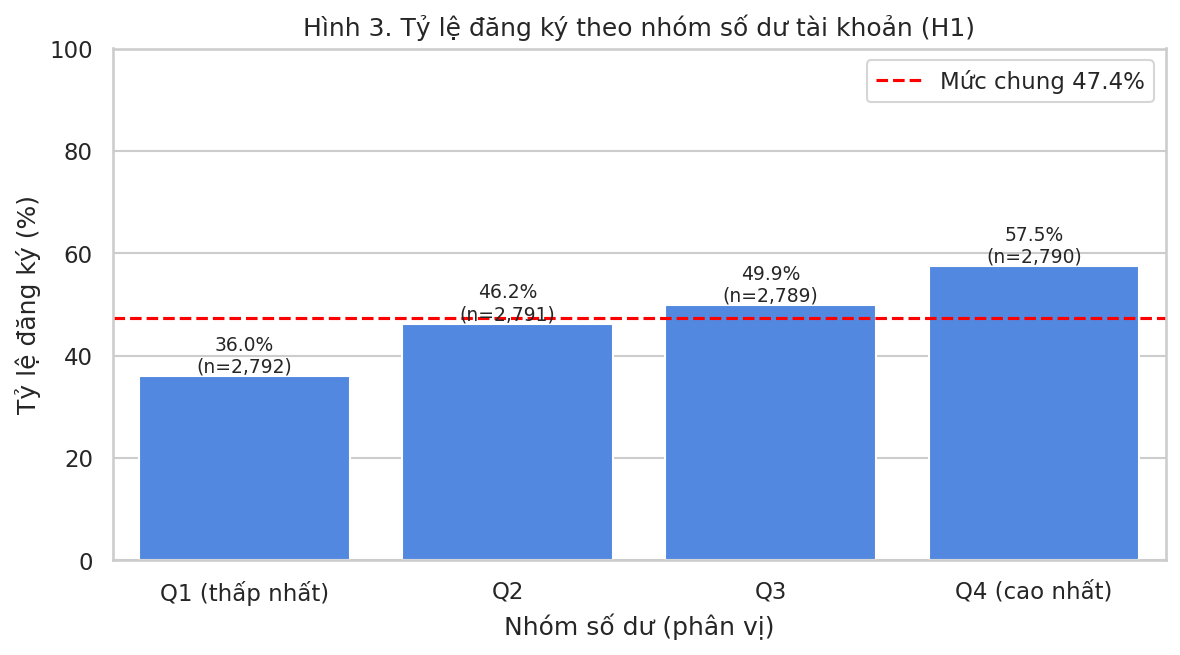

In [39]:
# H1: số dư tài khoản (chia 4 nhóm phân vị) vs tỷ lệ đăng ký
eda["balance_quartile"] = pd.qcut(eda["balance"], 4, labels=["Q1 (thấp nhất)", "Q2", "Q3", "Q4 (cao nhất)"])
t_bal = rate_table(eda, "balance_quartile")
print("Median balance theo deposit:\n", eda.groupby("deposit")["balance"].median())
print(t_bal)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=t_bal.index.astype(str), y=t_bal["ty_le_yes_%"], color="#3b82f6", ax=ax)
for i, (n, r) in enumerate(zip(t_bal["n"], t_bal["ty_le_yes_%"])):
    ax.text(i, r + 0.8, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
ax.axhline(overall_rate, color="red", ls="--", label=f"Mức chung {overall_rate:.1f}%")
ax.set_ylim(0, 100); ax.set_ylabel("Tỷ lệ đăng ký (%)"); ax.set_xlabel("Nhóm số dư (phân vị)")
ax.set_title("Hình 3. Tỷ lệ đăng ký theo nhóm số dư tài khoản (H1)"); ax.legend()
save_show("fig3_balance_quartile.png")

              n  ty_le_yes_%  median_balance
age_group                                   
18-25       450        71.11           480.0
26-35      3921        47.67           455.0
36-50      4320        41.37           549.5
51-60      1860        43.60           635.5
60+         611        82.16          1430.0


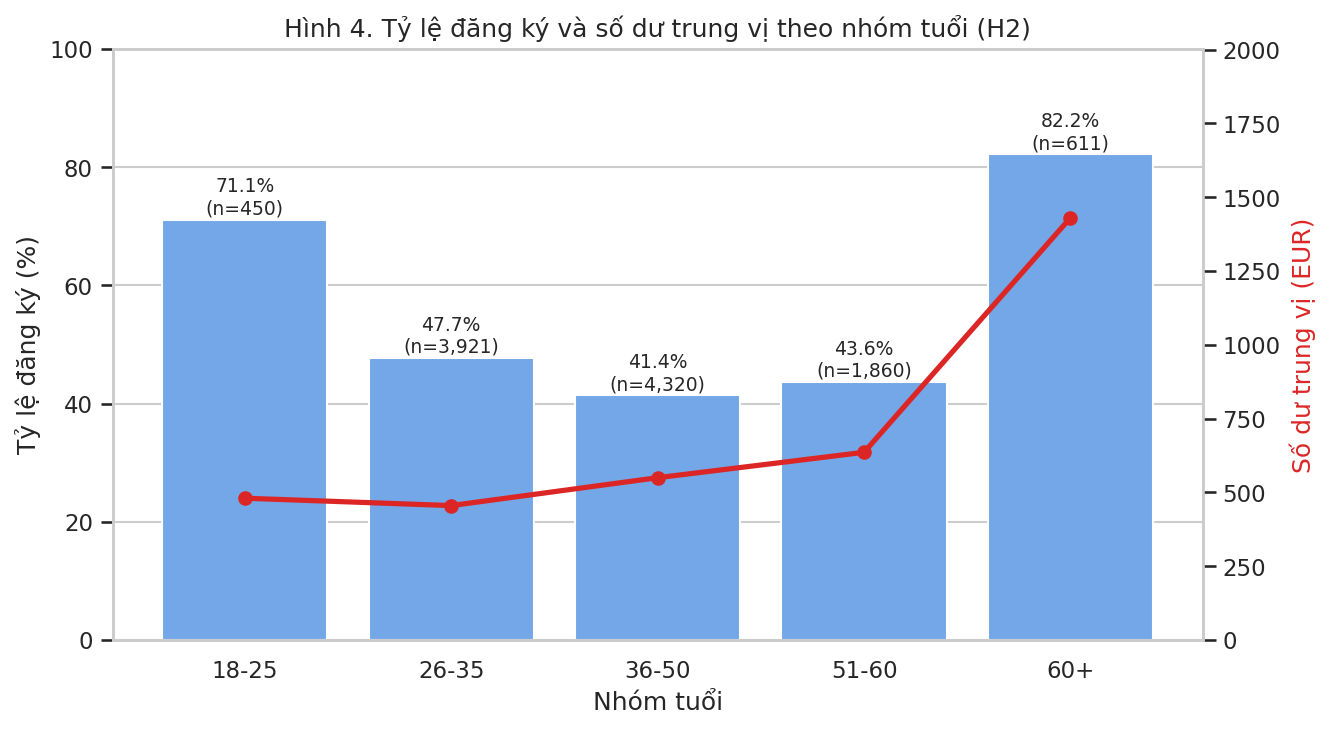

In [40]:
# H2: nhóm tuổi vs tỷ lệ đăng ký và số dư trung vị
t_age = rate_table(eda, "age_group")
t_age["median_balance"] = eda.groupby("age_group", observed=False)["balance"].median()
print(t_age)

fig, ax1 = plt.subplots(figsize=(9, 5))
sns.barplot(x=t_age.index.astype(str), y=t_age["ty_le_yes_%"], color="#60a5fa", ax=ax1)
for i, (n, r) in enumerate(zip(t_age["n"], t_age["ty_le_yes_%"])):
    ax1.text(i, r + 1, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
ax1.set_ylim(0, 100); ax1.set_ylabel("Tỷ lệ đăng ký (%)"); ax1.set_xlabel("Nhóm tuổi")
ax2 = ax1.twinx()
ax2.plot(range(len(t_age)), t_age["median_balance"], color="#dc2626", marker="o", lw=2.5)
ax2.set_ylim(0, t_age["median_balance"].max() * 1.4)
ax2.set_ylabel("Số dư trung vị (EUR)", color="#dc2626"); ax2.grid(False)
ax1.set_title("Hình 4. Tỷ lệ đăng ký và số dư trung vị theo nhóm tuổi (H2)")
save_show("fig4_age_group.png")

                   n  ty_le_yes_%
campaign_group                   
1               4798        53.38
2               3028        46.27
3               1321        46.78
4-5             1149        39.69
6+               866        29.21


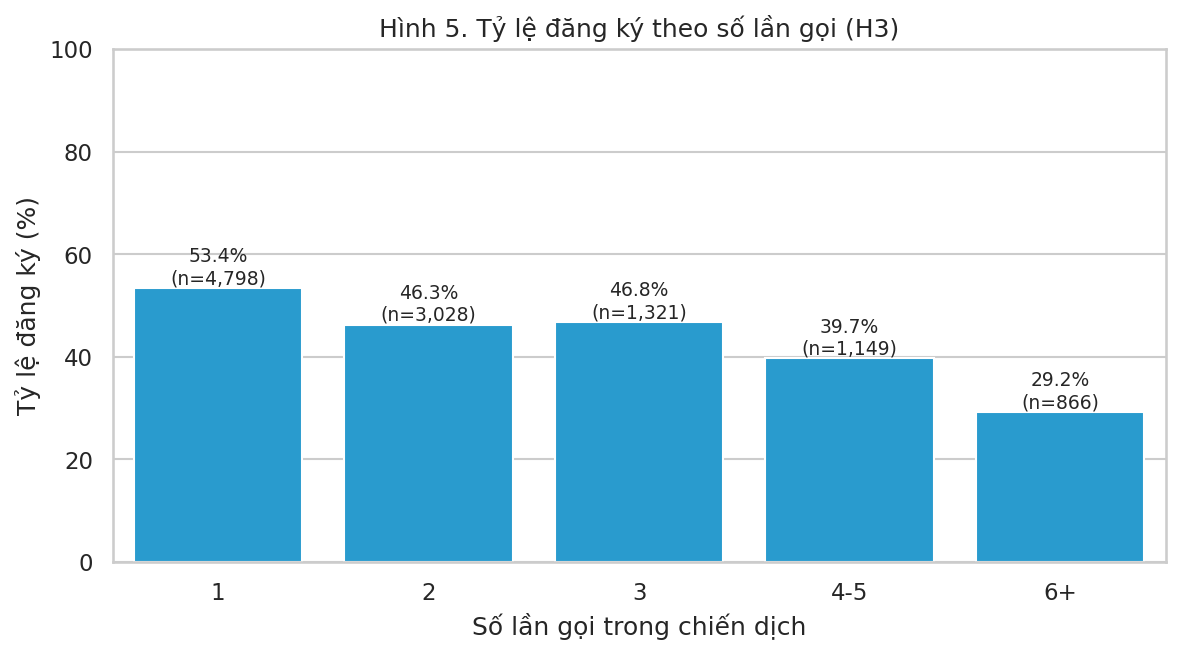

In [41]:
# H3: số lần gọi trong chiến dịch (campaign) vs tỷ lệ đăng ký
eda["campaign_group"] = pd.cut(eda["campaign"], bins=[0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"])
t_camp = rate_table(eda, "campaign_group")
print(t_camp)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=t_camp.index.astype(str), y=t_camp["ty_le_yes_%"], color="#0ea5e9", ax=ax)
for i, (n, r) in enumerate(zip(t_camp["n"], t_camp["ty_le_yes_%"])):
    ax.text(i, r + 0.8, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
ax.set_ylim(0, 100); ax.set_xlabel("Số lần gọi trong chiến dịch"); ax.set_ylabel("Tỷ lệ đăng ký (%)")
ax.set_title("Hình 5. Tỷ lệ đăng ký theo số lần gọi (H3)")
save_show("fig5_campaign.png")

Theo housing:
             n  ty_le_yes_%
housing                   
no       5881        57.03
yes      5281        36.64 

Theo loan:
          n  ty_le_yes_%
loan                   
no    9702        49.53
yes   1460        33.15


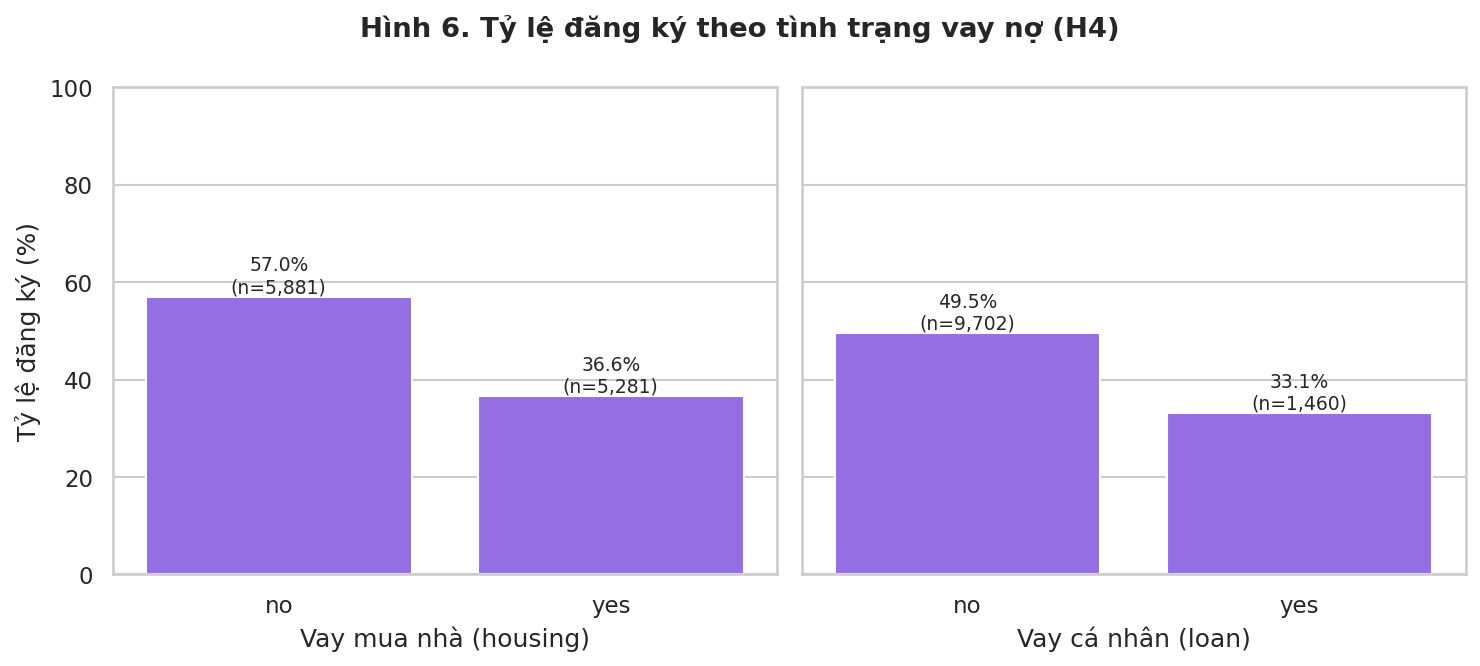

In [42]:
# H4: khoản vay mua nhà / vay cá nhân vs tỷ lệ đăng ký
t_house = rate_table(eda, "housing"); t_loan = rate_table(eda, "loan")
print("Theo housing:\n", t_house, "\n\nTheo loan:\n", t_loan)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, t, name in zip(axes, [t_house, t_loan], ["Vay mua nhà (housing)", "Vay cá nhân (loan)"]):
    sns.barplot(x=t.index.astype(str), y=t["ty_le_yes_%"], color="#8b5cf6", ax=ax)
    for i, (n, r) in enumerate(zip(t["n"], t["ty_le_yes_%"])):
        ax.text(i, r + 0.8, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
    ax.set_xlabel(name); ax.set_ylabel("Tỷ lệ đăng ký (%)"); ax.set_ylim(0, 100)
fig.suptitle("Hình 6. Tỷ lệ đăng ký theo tình trạng vay nợ (H4)", fontweight="bold")
save_show("fig6_housing_loan.png")

             n  ty_le_yes_%
poutcome                   
success   1071        91.32
other      537        57.17
failure   1228        50.33
unknown   8326        40.67


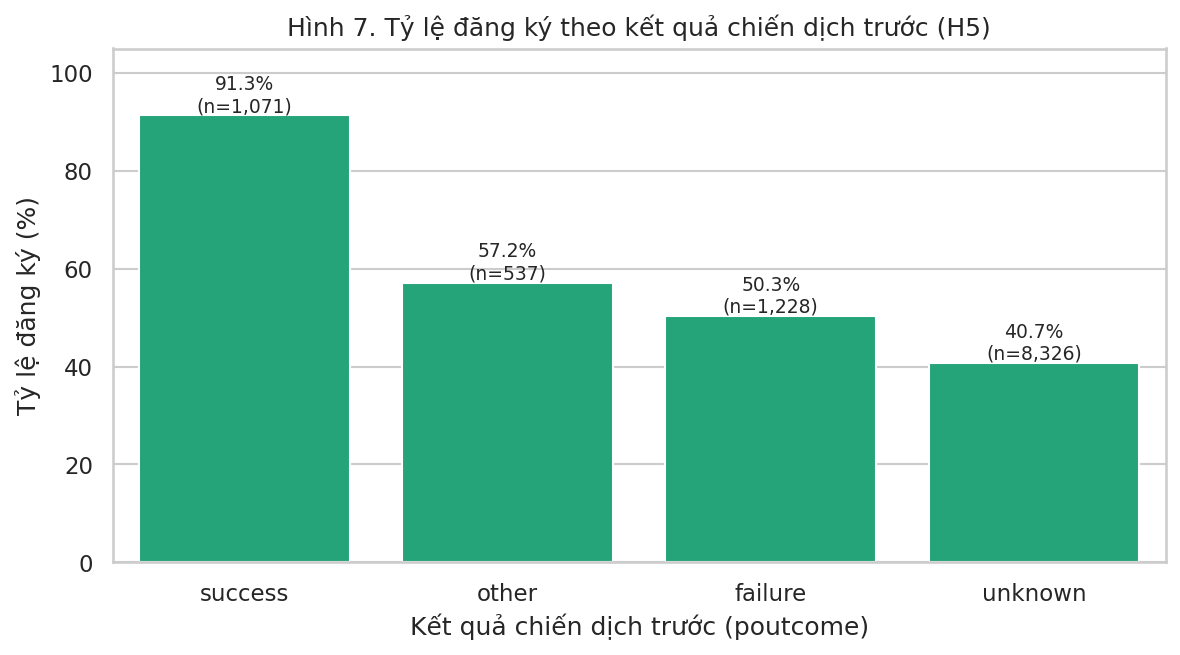

In [43]:
# H5: kết quả chiến dịch trước (poutcome) vs tỷ lệ đăng ký
t_pout = rate_table(eda, "poutcome").sort_values("ty_le_yes_%", ascending=False)
print(t_pout)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=t_pout.index.astype(str), y=t_pout["ty_le_yes_%"], color="#10b981", ax=ax)
for i, (n, r) in enumerate(zip(t_pout["n"], t_pout["ty_le_yes_%"])):
    ax.text(i, r + 0.8, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
ax.set_ylim(0, 105); ax.set_xlabel("Kết quả chiến dịch trước (poutcome)"); ax.set_ylabel("Tỷ lệ đăng ký (%)")
ax.set_title("Hình 7. Tỷ lệ đăng ký theo kết quả chiến dịch trước (H5)")
save_show("fig7_poutcome.png")

          n  ty_le_yes_%
month                   
jan     344        41.28
feb     776        56.83
mar     276        89.86
apr     923        62.51
may    2824        32.75
jun    1222        44.68
jul    1514        41.41
aug    1519        45.29
sep     319        84.33
oct     392        82.40
nov     943        42.74
dec     110        90.91


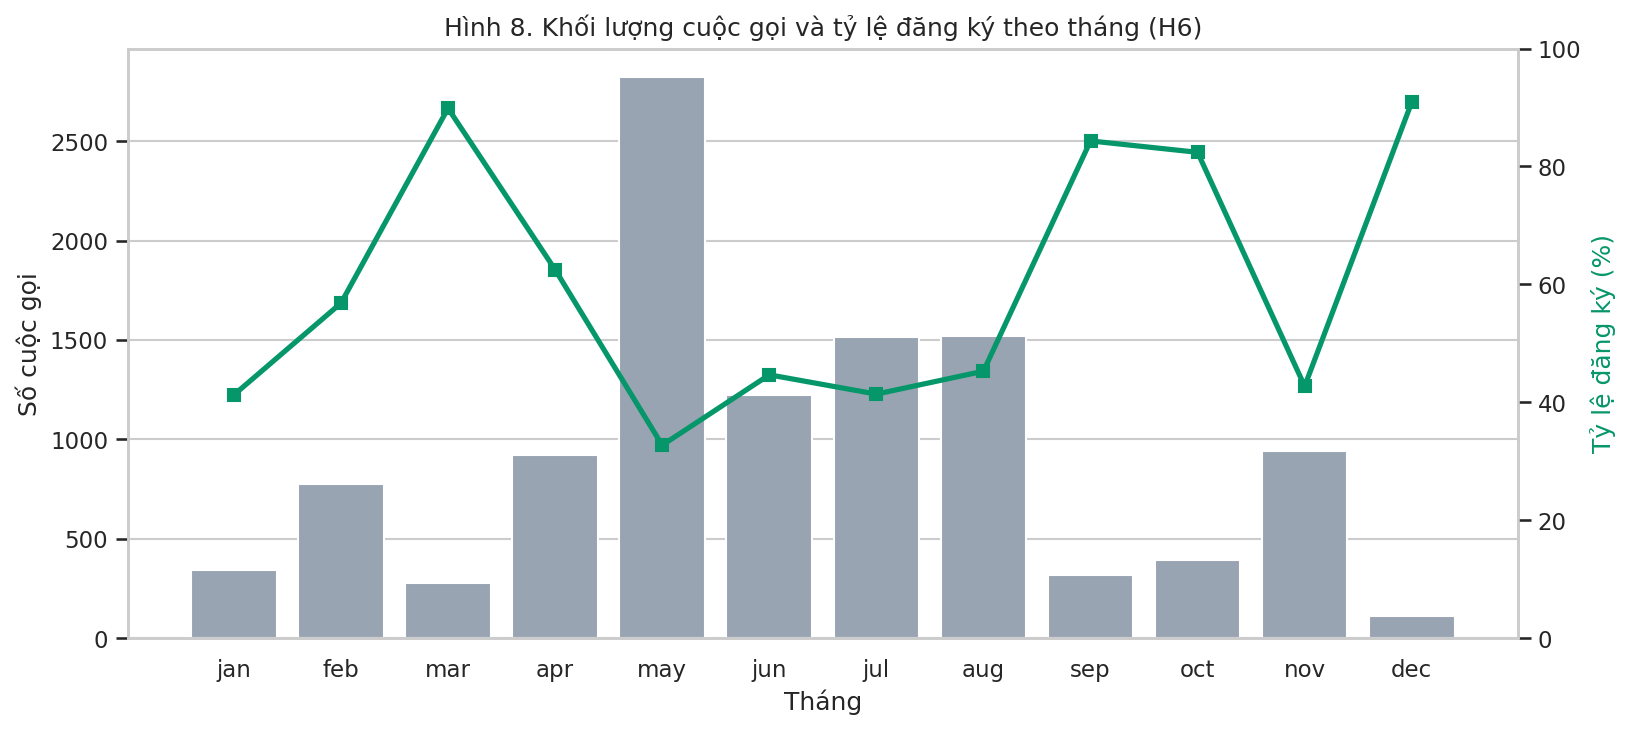

Lưu ý: các tháng có n nhỏ (ví dụ dec, mar, sep, oct, jan) có tỷ lệ dễ dao động mạnh, không nên diễn giải quá mức.


In [44]:
# H6: khối lượng cuộc gọi và tỷ lệ chuyển đổi theo tháng
month_order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
t_month = rate_table(eda, "month").reindex(month_order)
print(t_month)

fig, ax1 = plt.subplots(figsize=(11, 5))
sns.barplot(x=t_month.index, y=t_month["n"], color="#94a3b8", ax=ax1)
ax1.set_ylabel("Số cuộc gọi"); ax1.set_xlabel("Tháng")
ax2 = ax1.twinx()
ax2.plot(range(12), t_month["ty_le_yes_%"], color="#059669", marker="s", lw=2.5)
ax2.set_ylim(0, 100); ax2.set_ylabel("Tỷ lệ đăng ký (%)", color="#059669"); ax2.grid(False)
ax1.set_title("Hình 8. Khối lượng cuộc gọi và tỷ lệ đăng ký theo tháng (H6)")
save_show("fig8_month.png")
print("Lưu ý: các tháng có n nhỏ (ví dụ dec, mar, sep, oct, jan) có tỷ lệ dễ dao động mạnh, không nên diễn giải quá mức.")

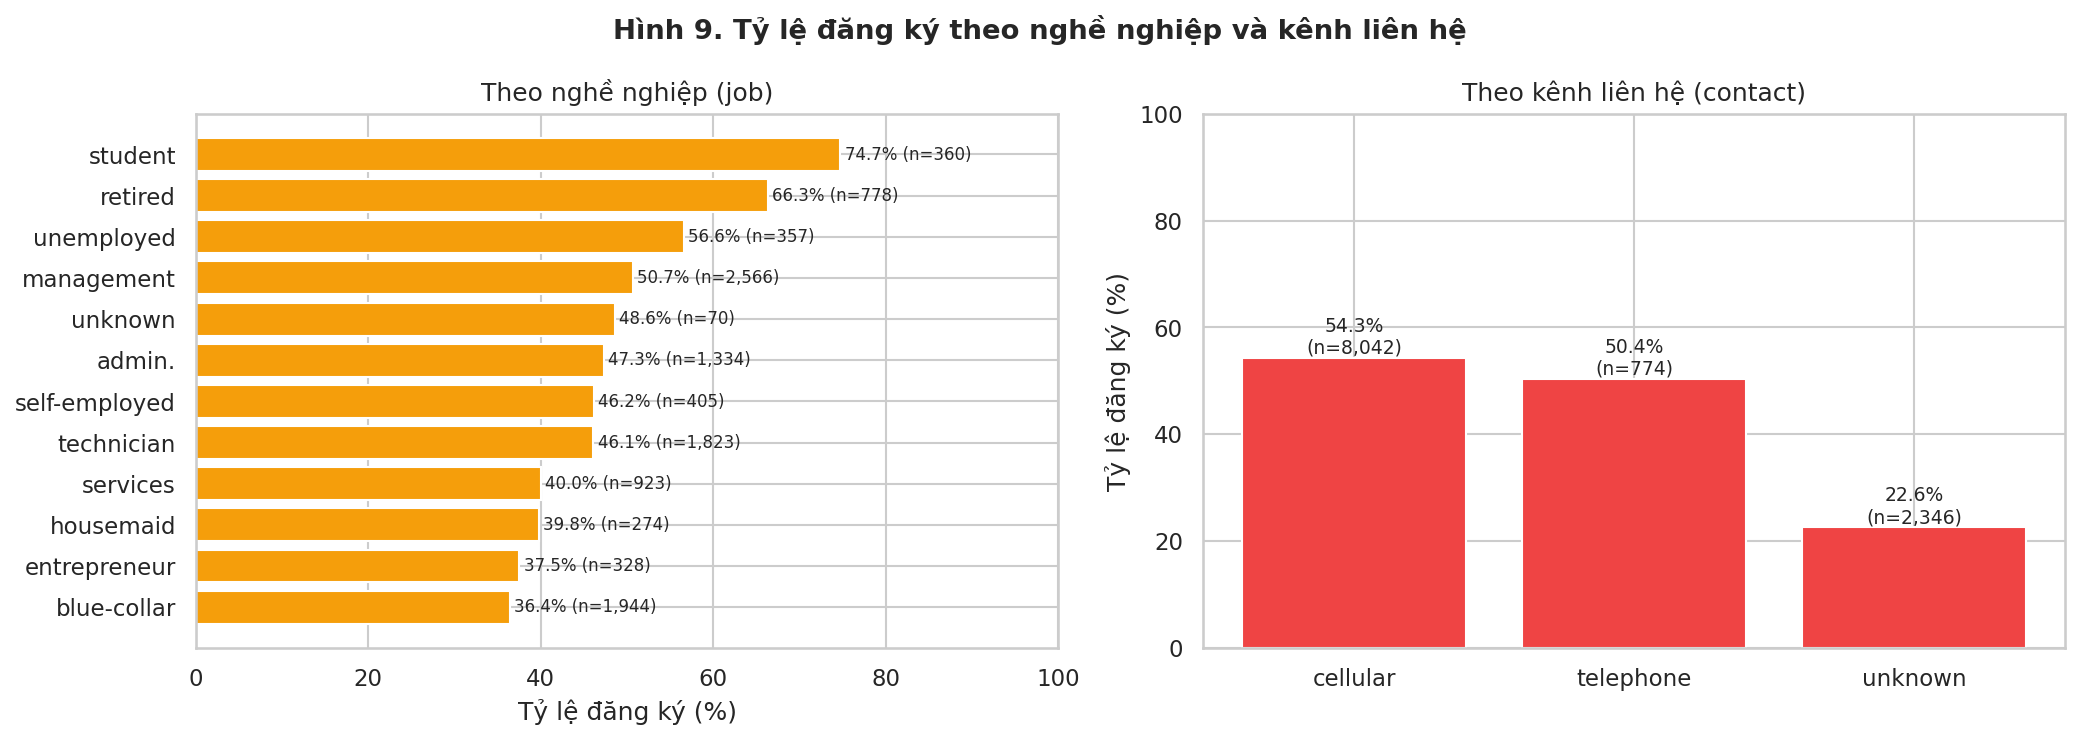

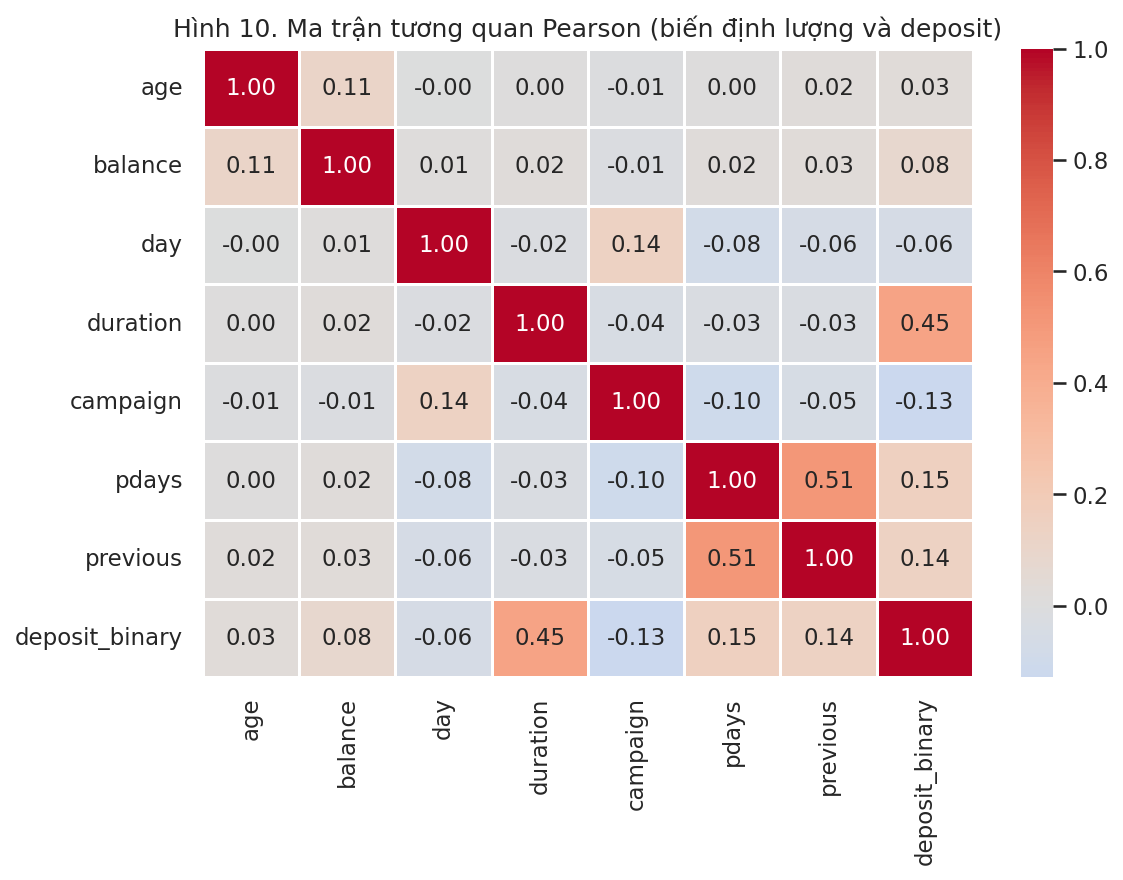

In [45]:
# Bổ sung: tỷ lệ đăng ký theo nghề nghiệp và kênh liên hệ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t_job = rate_table(eda, "job").sort_values("ty_le_yes_%", ascending=True)
axes[0].barh(t_job.index, t_job["ty_le_yes_%"], color="#f59e0b")
for i, (n, r) in enumerate(zip(t_job["n"], t_job["ty_le_yes_%"])):
    axes[0].text(r + 0.5, i, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].set_xlim(0, 100); axes[0].set_xlabel("Tỷ lệ đăng ký (%)"); axes[0].set_title("Theo nghề nghiệp (job)")
t_con = rate_table(eda, "contact")
axes[1].bar(t_con.index, t_con["ty_le_yes_%"], color="#ef4444")
for i, (n, r) in enumerate(zip(t_con["n"], t_con["ty_le_yes_%"])):
    axes[1].text(i, r + 0.8, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
axes[1].set_ylim(0, 100); axes[1].set_ylabel("Tỷ lệ đăng ký (%)"); axes[1].set_title("Theo kênh liên hệ (contact)")
fig.suptitle("Hình 9. Tỷ lệ đăng ký theo nghề nghiệp và kênh liên hệ", fontweight="bold")
save_show("fig9_job_contact.png")

# Ma trận tương quan Pearson giữa biến định lượng và mục tiêu
corr_df = df[num_cols].copy()
corr_df["deposit_binary"] = (df["deposit"] == "yes").astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Hình 10. Ma trận tương quan Pearson (biến định lượng và deposit)")
save_show("fig10_correlation.png")

In [46]:
# BẢNG TỔNG HỢP: Giả thuyết - Số liệu đối chiếu - Kết luận (tự tính từ dữ liệu, không ghi cứng)
def yes_rate(mask): return (eda.loc[mask, "deposit"] == "yes").mean() * 100

q4 = t_bal["ty_le_yes_%"].iloc[-1]; q1 = t_bal["ty_le_yes_%"].iloc[0]
a18, a60, a3650 = t_age.loc["18-25", "ty_le_yes_%"], t_age.loc["60+", "ty_le_yes_%"], t_age.loc["36-50", "ty_le_yes_%"]
c_le3, c_gt3 = yes_rate(eda["campaign"] <= 3), yes_rate(eda["campaign"] > 3)
h_no, h_yes = yes_rate(eda["housing"] == "no"), yes_rate(eda["housing"] == "yes")
l_no, l_yes = yes_rate(eda["loan"] == "no"), yes_rate(eda["loan"] == "yes")
p_succ, p_other = yes_rate(eda["poutcome"] == "success"), yes_rate(eda["poutcome"] != "success")
top_vol_month = t_month["n"].idxmax()
m_rate, m_n = t_month.loc[top_vol_month, "ty_le_yes_%"], t_month.loc[top_vol_month, "n"]

def verdict(ok): return "Số liệu ủng hộ" if ok else "Số liệu không ủng hộ"
summary = pd.DataFrame([
    ["H1", f"Q4 balance: {q4:.1f}% vs Q1: {q1:.1f}%", verdict(q4 > q1)],
    ["H2", f"18-25: {a18:.1f}%, 60+: {a60:.1f}% vs 36-50: {a3650:.1f}%", verdict(a18 > a3650 and a60 > a3650)],
    ["H3", f"campaign<=3: {c_le3:.1f}% vs >3: {c_gt3:.1f}%", verdict(c_le3 > c_gt3)],
    ["H4", f"housing=no: {h_no:.1f}% vs yes: {h_yes:.1f}%; loan=no: {l_no:.1f}% vs yes: {l_yes:.1f}%", verdict(h_no > h_yes and l_no > l_yes)],
    ["H5", f"success: {p_succ:.1f}% vs còn lại: {p_other:.1f}%", verdict(p_succ > p_other)],
    ["H6", f"Tháng nhiều cuộc gọi nhất: {top_vol_month} (n={m_n:,}) có tỷ lệ {m_rate:.1f}% vs chung {overall_rate:.1f}%", verdict(m_rate < overall_rate)],
], columns=["Giả thuyết", "Số liệu đối chiếu", "Kết luận (mô tả)"])
print(summary.to_string(index=False))
print("\nBảng trên trình bày so sánh mô tả. Các kiểm định thống kê về mối liên hệ được trình bày ở phần tiếp theo; các kết quả này không tự chứng minh quan hệ nhân quả.")

Giả thuyết                                                      Số liệu đối chiếu Kết luận (mô tả)
        H1                                         Q4 balance: 57.5% vs Q1: 36.0%   Số liệu ủng hộ
        H2                               18-25: 71.1%, 60+: 82.2% vs 36-50: 41.4%   Số liệu ủng hộ
        H3                                        campaign<=3: 50.1% vs >3: 35.2%   Số liệu ủng hộ
        H4          housing=no: 57.0% vs yes: 36.6%; loan=no: 49.5% vs yes: 33.2%   Số liệu ủng hộ
        H5                                       success: 91.3% vs còn lại: 42.7%   Số liệu ủng hộ
        H6 Tháng nhiều cuộc gọi nhất: may (n=2,824) có tỷ lệ 32.8% vs chung 47.4%   Số liệu ủng hộ

Bảng trên trình bày so sánh mô tả. Các kiểm định thống kê về mối liên hệ được trình bày ở phần tiếp theo; các kết quả này không tự chứng minh quan hệ nhân quả.


In [47]:
# KIỂM ĐỊNH GIẢ THUYẾT CHÍNH QUY
# Các phép kiểm định dưới đây mô tả mối liên hệ trong dữ liệu quan sát, không chứng minh nhân quả.
if USE_SCIPY_TESTS:
    from scipy import stats
    tests = []

    # H1: kiểm tra dịch chuyển thứ hạng balance giữa nhóm đăng ký và không đăng ký.
    yes_g, no_g = df[df.deposit == "yes"], df[df.deposit == "no"]
    u_bal, p_bal = stats.mannwhitneyu(yes_g["balance"], no_g["balance"], alternative="greater")
    tests.append({"Giả thuyết": "H1: Balance của nhóm deposit=yes có xu hướng cao hơn",
                  "Kiểm định": "Mann-Whitney U (một phía)", "Thống kê": f"U={u_bal:,.0f}", "p_raw": p_bal})

    # H2: nhóm tuổi và deposit.
    chi2_age, p_age, dof_age, _ = stats.chi2_contingency(pd.crosstab(eda["age_group"], eda["deposit"]))
    tests.append({"Giả thuyết": "H2: Tỷ lệ deposit khác nhau theo nhóm tuổi",
                  "Kiểm định": "Chi-square", "Thống kê": f"χ²={chi2_age:.2f}, df={dof_age}", "p_raw": p_age})

    # H3: liên hệ giữa số lần gọi và kết quả; chiều giảm được mô tả bằng tỷ lệ nhóm.
    chi2_camp, p_camp, dof_camp, _ = stats.chi2_contingency(pd.crosstab(eda["campaign_group"], eda["deposit"]))
    tests.append({"Giả thuyết": "H3: Tỷ lệ deposit có liên hệ với nhóm số lần gọi",
                  "Kiểm định": "Chi-square", "Thống kê": f"χ²={chi2_camp:.2f}, df={dof_camp}", "p_raw": p_camp})

    # H4: kiểm định độc lập riêng cho hai loại khoản vay.
    for col, label in [("housing", "H4a: Tỷ lệ deposit khác nhau theo housing"),
                       ("loan", "H4b: Tỷ lệ deposit khác nhau theo loan")]:
        chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(eda[col], eda["deposit"]))
        tests.append({"Giả thuyết": label, "Kiểm định": "Chi-square",
                      "Thống kê": f"χ²={chi2:.2f}, df={dof}", "p_raw": p})

    # H5: kết quả chiến dịch trước.
    chi2_pout, p_pout, dof_pout, _ = stats.chi2_contingency(pd.crosstab(eda["poutcome"], eda["deposit"]))
    tests.append({"Giả thuyết": "H5: Tỷ lệ deposit khác nhau theo poutcome",
                  "Kiểm định": "Chi-square", "Thống kê": f"χ²={chi2_pout:.2f}, df={dof_pout}", "p_raw": p_pout})

    # H6: tháng và kết quả.
    chi2_mon, p_mon, dof_mon, _ = stats.chi2_contingency(pd.crosstab(eda["month"], eda["deposit"]))
    tests.append({"Giả thuyết": "H6: Tỷ lệ deposit khác nhau theo tháng",
                  "Kiểm định": "Chi-square", "Thống kê": f"χ²={chi2_mon:.2f}, df={dof_mon}", "p_raw": p_mon})

    # Hiệu chỉnh Holm để kiểm soát family-wise error cho nhiều kiểm định.
    order = sorted(range(len(tests)), key=lambda i: tests[i]["p_raw"])
    adjusted = [0.0] * len(tests)
    running_max = 0.0
    m = len(tests)
    for rank, idx in enumerate(order):
        running_max = max(running_max, (m - rank) * tests[idx]["p_raw"])
        adjusted[idx] = min(1.0, running_max)
    for i, row in enumerate(tests):
        row["p_Holm"] = adjusted[i]
        row["Kết luận (α=0.05)"] = ("Có bằng chứng về mối liên hệ" if adjusted[i] < 0.05
                                     else "Chưa đủ bằng chứng về mối liên hệ")
    df_tests = pd.DataFrame(tests)
    df_tests["p_raw"] = df_tests["p_raw"].map(lambda p: f"{p:.3e}")
    df_tests["p_Holm"] = df_tests["p_Holm"].map(lambda p: f"{p:.3e}")
    print("Các kiểm định dùng α=0.05; p_Holm đã hiệu chỉnh Holm cho 7 giả thuyết.")
    print(df_tests.to_string(index=False))
else:
    print("Đã tắt kiểm định SciPy; chỉ sử dụng thống kê mô tả.")

Các kiểm định dùng α=0.05; p_Holm đã hiệu chỉnh Holm cho 7 giả thuyết.
                                          Giả thuyết                 Kiểm định          Thống kê      p_raw     p_Holm            Kết luận (α=0.05)
H1: Balance của nhóm deposit=yes có xu hướng cao hơn Mann-Whitney U (một phía)      U=18,360,634  1.563e-62  4.690e-62 Có bằng chứng về mối liên hệ
          H2: Tỷ lệ deposit khác nhau theo nhóm tuổi                Chi-square   χ²=471.56, df=4 9.487e-101 3.795e-100 Có bằng chứng về mối liên hệ
    H3: Tỷ lệ deposit có liên hệ với nhóm số lần gọi                Chi-square   χ²=212.78, df=4  6.697e-45  1.339e-44 Có bằng chứng về mối liên hệ
           H4a: Tỷ lệ deposit khác nhau theo housing                Chi-square   χ²=463.19, df=1 9.724e-103 4.862e-102 Có bằng chứng về mối liên hệ
              H4b: Tỷ lệ deposit khác nhau theo loan                Chi-square   χ²=135.83, df=1  2.171e-31  2.171e-31 Có bằng chứng về mối liên hệ
           H5: Tỷ lệ deposit khác nhau th

## Phần B – So sánh các mô hình phân loại

Mục tiêu chính là dự đoán đăng ký tiền gửi **trước cuộc gọi**; vì vậy `duration` không được dùng làm đặc trưng trong mô hình chính. Một bộ mô hình bổ sung có `duration` được giữ lại để minh họa mức độ thay đổi hiệu năng khi sử dụng thông tin chỉ có sau cuộc gọi.

Bốn mô hình được so sánh gồm Logistic Regression, KNN, Decision Tree và Random Forest. Logistic Regression và KNN sử dụng đặc trưng đã chuẩn hóa; Decision Tree và Random Forest sử dụng đặc trưng chưa chuẩn hóa. Các mô hình dùng cùng tập train/test và tham số được ấn định trước khi đánh giá.

In [48]:
# Khai báo 4 mô hình và hàm đánh giá
def build_models():
    return {
        "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True),
        "KNN (k=15)": (KNeighborsClassifier(n_neighbors=15), True),
        "Decision Tree (depth=6)": (DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), False),
        "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1), False),
    }
# True = dùng dữ liệu đã chuẩn hóa RobustScaler; False = dữ liệu gốc

feature_sets = {"Pre-call (chính)": pre_cols, "Post-call (tham chiếu, có duration)": post_cols}
results, store = [], {}

for fs_name, cols in feature_sets.items():
    for m_name, (model, use_scaled) in build_models().items():
        Xtr = (X_train_scaled_full if use_scaled else X_train_full)[cols]
        Xte = (X_test_scaled_full if use_scaled else X_test_full)[cols]
        model.fit(Xtr, y_train)
        pred_tr, pred_te = model.predict(Xtr), model.predict(Xte)
        prob_te = model.predict_proba(Xte)[:, 1]
        results.append({
            "Bộ đặc trưng": fs_name, "Mô hình": m_name,
            "Acc train": accuracy_score(y_train, pred_tr), "Acc test": accuracy_score(y_test, pred_te),
            "Precision": precision_score(y_test, pred_te), "Recall": recall_score(y_test, pred_te),
            "F1": f1_score(y_test, pred_te), "ROC-AUC": roc_auc_score(y_test, prob_te)})
        store[(fs_name, m_name)] = {"model": model, "pred": pred_te, "prob": prob_te, "cols": cols}

res = pd.DataFrame(results)
res["Chênh lệch train-test"] = res["Acc train"] - res["Acc test"]
pd.set_option("display.width", 200)
print(res.round(4).to_string(index=False))

                       Bộ đặc trưng                 Mô hình  Acc train  Acc test  Precision  Recall     F1  ROC-AUC  Chênh lệch train-test
                   Pre-call (chính)     Logistic Regression     0.7127    0.7022     0.7411  0.5709 0.6450   0.7594                 0.0105
                   Pre-call (chính)              KNN (k=15)     0.7396    0.7049     0.7254  0.6068 0.6608   0.7521                 0.0347
                   Pre-call (chính) Decision Tree (depth=6)     0.6967    0.6928     0.7274  0.5624 0.6343   0.7430                 0.0039
                   Pre-call (chính)           Random Forest     0.8029    0.7318     0.7782  0.6068 0.6819   0.7863                 0.0711
Post-call (tham chiếu, có duration)     Logistic Regression     0.8278    0.8285     0.8261  0.8081 0.8170   0.9075                -0.0007
Post-call (tham chiếu, có duration)              KNN (k=15)     0.8409    0.8298     0.8241  0.8147 0.8194   0.8960                 0.0110
Post-call (tham chiếu, có d

In [49]:
# Bảng so sánh gọn cho mô hình CHÍNH (pre-call)
main = res[res["Bộ đặc trưng"] == "Pre-call (chính)"].set_index("Mô hình").drop(columns="Bộ đặc trưng")
print("BẢNG SO SÁNH 4 MÔ HÌNH – DỰ ĐOÁN TRƯỚC CUỘC GỌI (tập test)")
main.round(4)

BẢNG SO SÁNH 4 MÔ HÌNH – DỰ ĐOÁN TRƯỚC CUỘC GỌI (tập test)


,Acc train,Acc test,Precision,Recall,F1,ROC-AUC,Chênh lệch train-test
Mô hình,,,,,,,
Logistic Regression,0.7127,0.7022,0.7411,0.5709,0.6450,0.7594,0.0105
KNN (k=15),0.7396,0.7049,0.7254,0.6068,0.6608,0.7521,0.0347
Decision Tree (depth=6),0.6967,0.6928,0.7274,0.5624,0.6343,0.7430,0.0039
Random Forest,0.8029,0.7318,0.7782,0.6068,0.6819,0.7863,0.0711


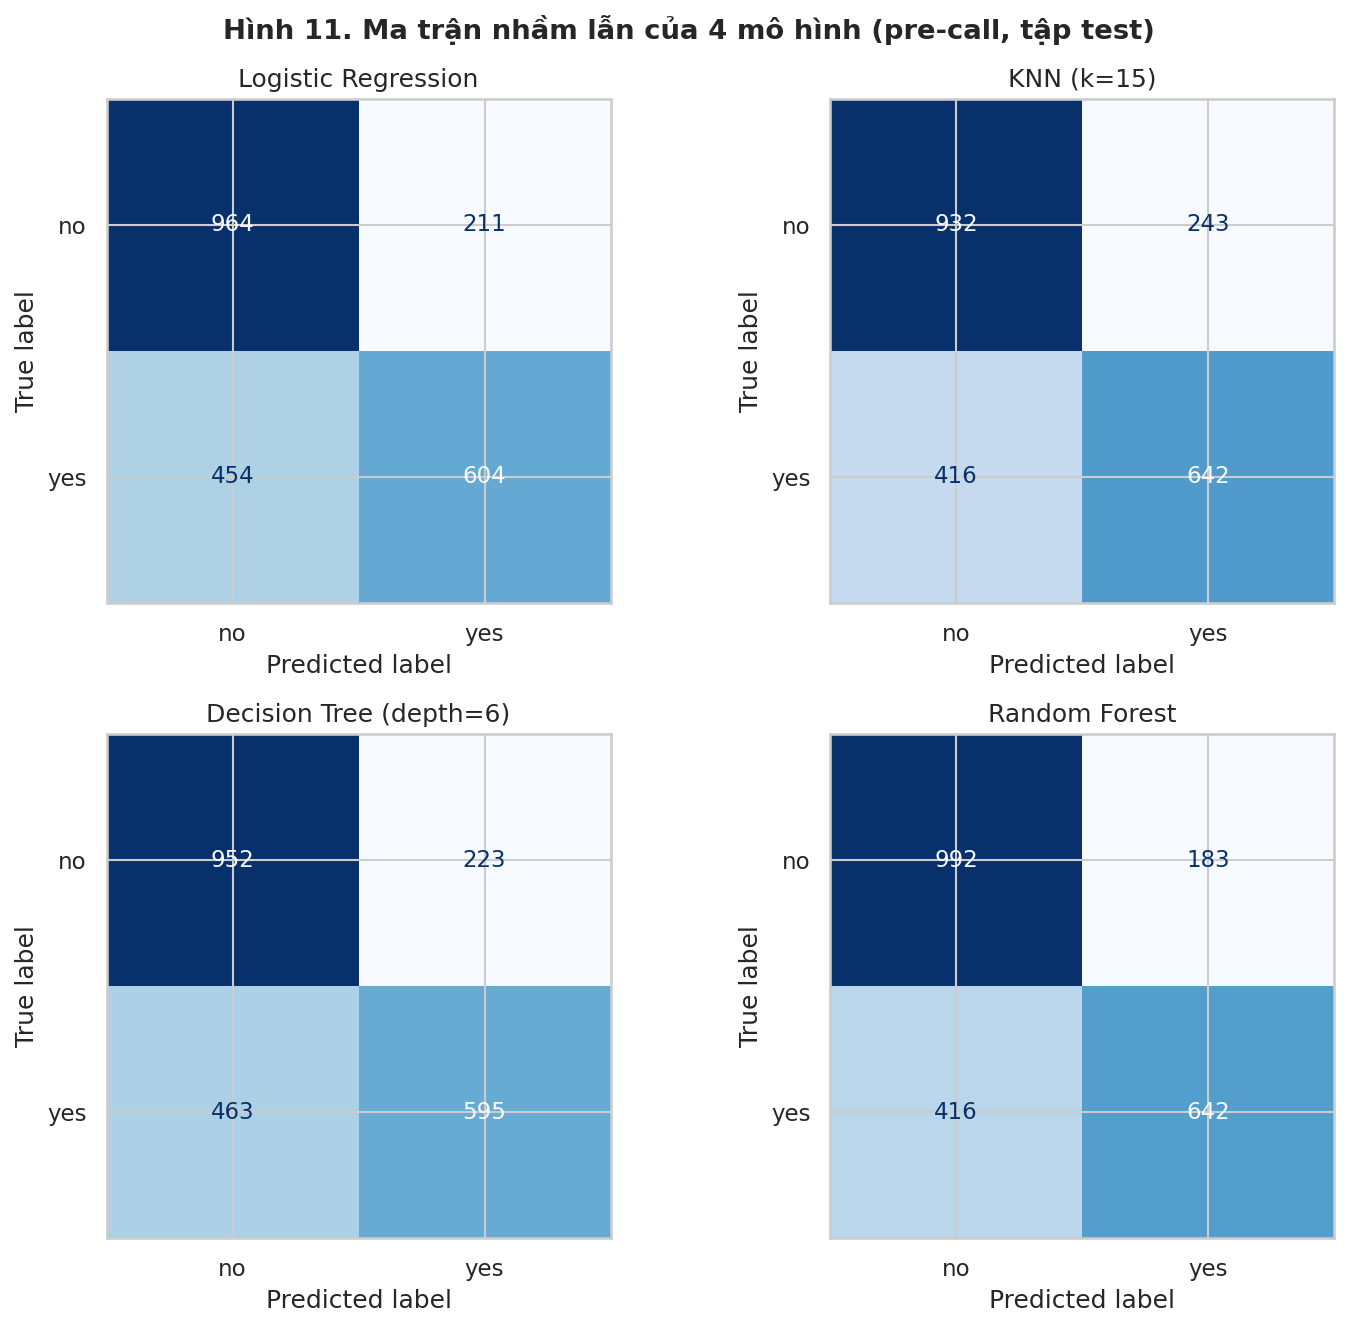

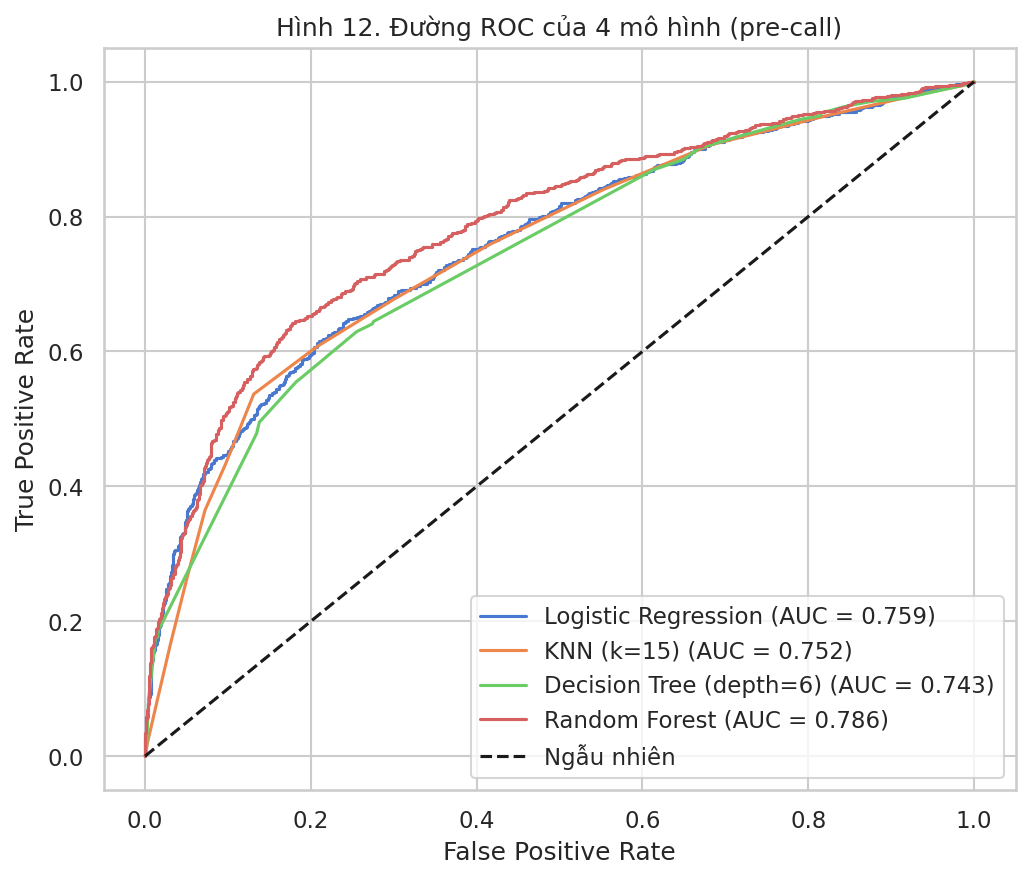

In [50]:
# Ma trận nhầm lẫn của 4 mô hình (pre-call)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, m_name in zip(axes.ravel(), build_models().keys()):
    s = store[("Pre-call (chính)", m_name)]
    ConfusionMatrixDisplay(confusion_matrix(y_test, s["pred"]), display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(m_name)
fig.suptitle("Hình 11. Ma trận nhầm lẫn của 4 mô hình (pre-call, tập test)", fontweight="bold")
save_show("fig11_confusion_matrices.png")

# Đường ROC của 4 mô hình
plt.figure(figsize=(7, 6))
for m_name in build_models().keys():
    s = store[("Pre-call (chính)", m_name)]
    fpr, tpr, _ = roc_curve(y_test, s["prob"])
    auc = roc_auc_score(y_test, s["prob"])
    plt.plot(fpr, tpr, label=f"{m_name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Ngẫu nhiên")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Hình 12. Đường ROC của 4 mô hình (pre-call)"); plt.legend(loc="lower right")
save_show("fig12_roc_curves.png")

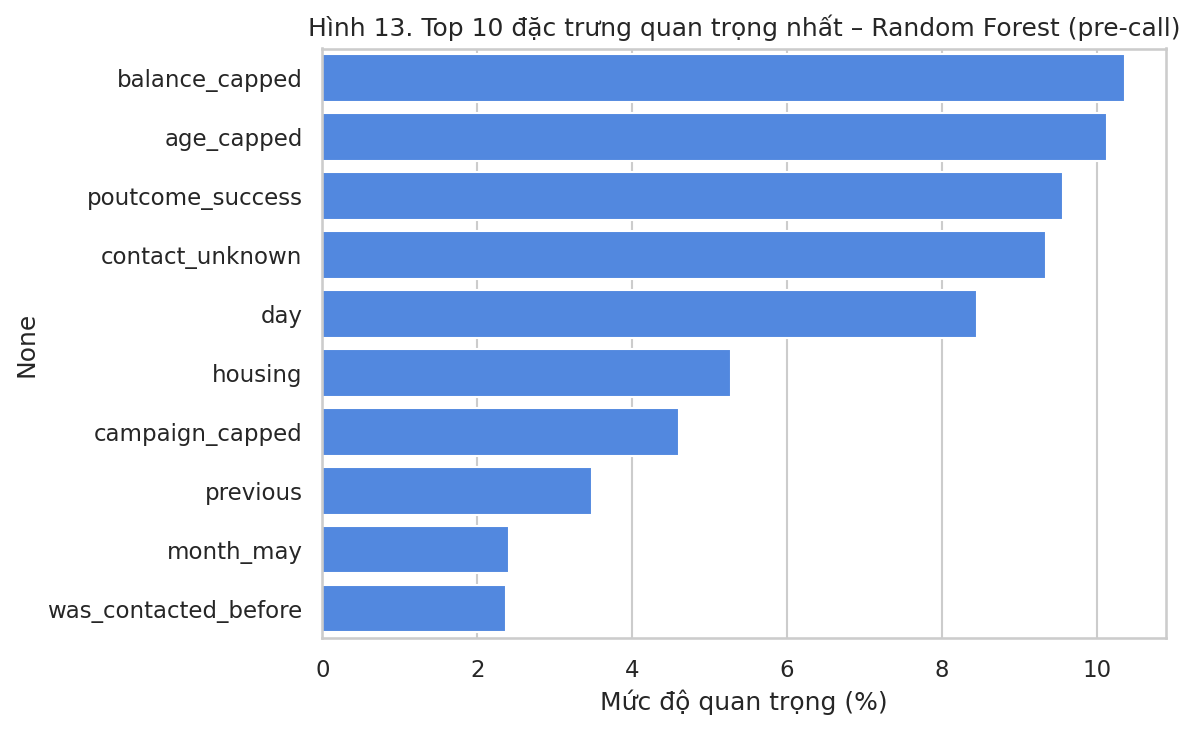

balance_capped          10.37
age_capped              10.14
poutcome_success         9.56
contact_unknown          9.34
day                      8.46
housing                  5.28
campaign_capped          4.61
previous                 3.48
month_may                2.40
was_contacted_before     2.38
dtype: float64


In [51]:
# Feature importance của Random Forest (pre-call). Lưu ý: đây là mức độ đóng góp vào dự đoán, KHÔNG phải quan hệ nhân quả.
rf = store[("Pre-call (chính)", "Random Forest")]["model"]
imp = pd.Series(rf.feature_importances_, index=pre_cols).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values * 100, y=imp.index, color="#3b82f6")
plt.xlabel("Mức độ quan trọng (%)"); plt.title("Hình 13. Top 10 đặc trưng quan trọng nhất – Random Forest (pre-call)")
save_show("fig13_feature_importance.png")
print((imp * 100).round(2))

In [52]:
# Kết quả phân loại chi tiết cho mô hình pre-call có ROC-AUC cao nhất
best_name = main["ROC-AUC"].idxmax()
print("Mô hình có ROC-AUC cao nhất (pre-call):", best_name)
print(classification_report(y_test, store[("Pre-call (chính)", best_name)]["pred"], target_names=["no", "yes"], digits=3))

# Minh chứng data leakage của 'duration'
leak = res.pivot(index="Mô hình", columns="Bộ đặc trưng", values="ROC-AUC")
leak["Chênh lệch AUC (post - pre)"] = leak["Post-call (tham chiếu, có duration)"] - leak["Pre-call (chính)"]
print("\nSO SÁNH ROC-AUC KHI CÓ / KHÔNG CÓ 'duration':")
print(leak.round(4))

Mô hình có ROC-AUC cao nhất (pre-call): Random Forest
              precision    recall  f1-score   support

          no      0.705     0.844     0.768      1175
         yes      0.778     0.607     0.682      1058

    accuracy                          0.732      2233
   macro avg      0.741     0.726     0.725      2233
weighted avg      0.739     0.732     0.727      2233


SO SÁNH ROC-AUC KHI CÓ / KHÔNG CÓ 'duration':
Bộ đặc trưng             Post-call (tham chiếu, có duration)  Pre-call (chính)  Chênh lệch AUC (post - pre)
Mô hình                                                                                                    
Decision Tree (depth=6)                               0.8816            0.7430                       0.1386
KNN (k=15)                                            0.8960            0.7521                       0.1439
Logistic Regression                                   0.9075            0.7594                       0.1480
Random Forest                   

### Cách đọc kết quả mô hình

- So sánh Accuracy train và test để xem xét chênh lệch hiệu năng; kết hợp với các chỉ số trên tập test để đánh giá khả năng nhận diện lớp `yes`.
- Precision cho biết tỷ lệ dự đoán `yes` đúng trong số các khách hàng được dự đoán là `yes`; Recall cho biết tỷ lệ khách hàng thực sự đăng ký được mô hình nhận diện. ROC-AUC đo khả năng xếp hạng hai lớp trên nhiều ngưỡng.
- Việc thêm `duration` có thể làm chỉ số dự đoán tăng, nhưng biến này chỉ được biết sau cuộc gọi nên không phù hợp với mục tiêu pre-call.
- Feature importance mô tả mức độ mô hình sử dụng từng biến, không đo lường tác động nhân quả.
- Khi diễn giải biểu đồ, cần nêu câu hỏi phân tích, nhóm đối chiếu, tỷ lệ và cỡ mẫu liên quan, nhận định chính cùng giới hạn suy luận. Với ma trận nhầm lẫn và ROC, chỉ diễn giải kết quả trên tập test.

# Giai đoạn 4: Đánh giá kết quả và khuyến nghị quản trị

Các kết quả định lượng được tổng hợp từ dữ liệu và phép đánh giá trên tập test. Khuyến nghị dưới đây là các hướng hành động cần được xác nhận bằng thử nghiệm thực tế; các tỷ lệ quan sát không được diễn giải như tác động nhân quả.

In [53]:
# Tổng hợp tự động các phát hiện nổi bật (không ghi cứng số liệu)
print("=== PHÁT HIỆN NỔI BẬT ===")
print(f"- Tỷ lệ đăng ký chung: {overall_rate:.2f}% trên {len(df):,} khách hàng")

best_seg = t_pout["ty_le_yes_%"].idxmax()
print(f"- Nhóm poutcome có tỷ lệ cao nhất: '{best_seg}' = {t_pout.loc[best_seg, 'ty_le_yes_%']:.1f}% (n={t_pout.loc[best_seg, 'n']:,})")

age_best = t_age["ty_le_yes_%"].idxmax()
print(f"- Nhóm tuổi có tỷ lệ cao nhất: {age_best} = {t_age.loc[age_best, 'ty_le_yes_%']:.1f}% (n={t_age.loc[age_best, 'n']:,})")

big_months = t_month[t_month["n"] >= 500]
bm_best, bm_worst = big_months["ty_le_yes_%"].idxmax(), big_months["ty_le_yes_%"].idxmin()
print(f"- Trong các tháng có >= 500 cuộc gọi: cao nhất = {bm_best} ({big_months.loc[bm_best,'ty_le_yes_%']:.1f}%), thấp nhất = {bm_worst} ({big_months.loc[bm_worst,'ty_le_yes_%']:.1f}%)")

print(f"- Mô hình dự đoán trước cuộc gọi tốt nhất theo ROC-AUC: {best_name} (AUC = {main.loc[best_name,'ROC-AUC']:.3f}, F1 = {main.loc[best_name,'F1']:.3f})")
rf_gap = leak.loc["Random Forest", "Chênh lệch AUC (post - pre)"]
print(f"- Thêm 'duration' làm ROC-AUC của Random Forest tăng {rf_gap:.3f} -> dấu hiệu data leakage nếu dùng để dự đoán trước cuộc gọi")

=== PHÁT HIỆN NỔI BẬT ===
- Tỷ lệ đăng ký chung: 47.38% trên 11,162 khách hàng
- Nhóm poutcome có tỷ lệ cao nhất: 'success' = 91.3% (n=1,071)
- Nhóm tuổi có tỷ lệ cao nhất: 60+ = 82.2% (n=611)
- Trong các tháng có >= 500 cuộc gọi: cao nhất = apr (62.5%), thấp nhất = may (32.8%)
- Mô hình dự đoán trước cuộc gọi tốt nhất theo ROC-AUC: Random Forest (AUC = 0.786, F1 = 0.682)
- Thêm 'duration' làm ROC-AUC của Random Forest tăng 0.132 -> dấu hiệu data leakage nếu dùng để dự đoán trước cuộc gọi


## Khuyến nghị quản trị và hướng nghiên cứu

### 1. Phân khúc khách hàng

- Nhóm có `poutcome = success` có tỷ lệ đăng ký quan sát cao. Có thể xem xét ưu tiên liên hệ nhóm này trong một pilot, đồng thời theo dõi quy mô mẫu và kết quả trên nhóm khách hàng tương đương.
- Tỷ lệ đăng ký quan sát khác nhau theo nhóm tuổi và tình trạng khoản vay. Đây có thể là cơ sở để thiết kế thông điệp phù hợp; cần đánh giá thêm khả năng tiếp cận và tính công bằng trước khi triển khai.

### 2. Tần suất và thời điểm liên hệ

Trong dữ liệu, tỷ lệ đăng ký thấp hơn ở các nhóm được gọi nhiều lần. Mối liên hệ này không chứng minh gọi nhiều làm giảm khả năng đăng ký, vì khách hàng khó chuyển đổi có thể đã được gọi nhiều hơn. Có thể thiết kế thử nghiệm ngẫu nhiên so sánh giới hạn tối đa 3 lần gọi với quy trình hiện tại. Trước khi thử nghiệm, đơn vị vận hành cần xác định thời hạn, cỡ mẫu và ngưỡng cải thiện tối thiểu dựa trên chi phí và năng lực liên hệ. Theo dõi tỷ lệ đăng ký, số cuộc gọi trên mỗi đăng ký và phản hồi khách hàng.

Tháng có lượng cuộc gọi cao nhất không nhất thiết có tỷ lệ đăng ký cao. Việc phân bổ lại nguồn lực sang tháng có kết quả quan sát tốt hơn cần được thử nghiệm và kiểm soát khác biệt về cơ cấu khách hàng cũng như quy mô mẫu.

### 3. Mô hình xếp hạng khách hàng trước cuộc gọi

Random Forest được so sánh với ba mô hình còn lại trên tập test và là một ứng viên để xếp hạng khách hàng. Trước khi đưa vào CRM, nên so sánh ngẫu nhiên nhóm dùng lead scoring với nhóm theo quy trình hiện tại. Ngân hàng cần xác định trước thời hạn thử nghiệm, cỡ mẫu và ngưỡng cải thiện tối thiểu dựa trên chi phí và năng lực vận hành; theo dõi tỷ lệ đăng ký, Precision, Recall và số cuộc gọi trên mỗi đăng ký. Chưa thể tính ROI từ bộ dữ liệu hiện tại vì không có chi phí cuộc gọi.

Không đưa `duration` vào mô hình dự đoán trước cuộc gọi vì biến này chỉ được xác định sau khi cuộc gọi kết thúc.

### 4. Giới hạn và hướng mở rộng

Dữ liệu không có thu nhập hàng tháng, giá trị tiền gửi thực tế hoặc chi phí mỗi cuộc gọi. Trong lần chạy được ghi nhận, Accuracy của Random Forest trên train là 0,803 và trên test là 0,732, chênh lệch 0,071; khoảng cách này gợi ý khả năng overfitting và cho thấy dấu hiệu overfitting; cần kiểm tra thêm bằng cross-validation hoặc dữ liệu từ giai đoạn khác. Các siêu tham số được cố định, chưa tối ưu hóa. Việc đánh giá dựa trên một lần chia train/test nên kết quả có thể phụ thuộc vào cách chia và chưa phản ánh đầy đủ khả năng dự đoán dữ liệu tương lai. `previous` có phân phối lệch phải mạnh; dù được chuẩn hóa bằng RobustScaler, các giá trị lớn vẫn có thể ảnh hưởng đến Logistic Regression và KNN.

Nghiên cứu tiếp theo có thể bổ sung cross-validation và kiểm thử theo thời gian, tối ưu ngưỡng phân loại theo chi phí, đồng thời tiến hành A/B testing trong vận hành.

In [54]:
# Liệt kê các biểu đồ được tạo trong thư mục đầu ra
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", os.path.join(OUTPUT_DIR, f))
print("\nHoàn tất quá trình phân tích.")

 - figures_output/fig10_correlation.png
 - figures_output/fig11_confusion_matrices.png
 - figures_output/fig12_roc_curves.png
 - figures_output/fig13_feature_importance.png
 - figures_output/fig1_boxplot_outliers.png
 - figures_output/fig2_histogram_skew.png
 - figures_output/fig3_balance_quartile.png
 - figures_output/fig4_age_group.png
 - figures_output/fig5_campaign.png
 - figures_output/fig6_housing_loan.png
 - figures_output/fig7_poutcome.png
 - figures_output/fig8_month.png
 - figures_output/fig9_job_contact.png

Hoàn tất quá trình phân tích.
